<h1>Identifying U.S. Economic and Financial Market Regimes Using Machine Learning</h1>

<h3>Capstone Project Overview 20.1</h3>

This project explores whether Machine Learning algorithms can identify different U.S. economic and financial market regimes using historical stock market and macroeconomic data.

I used Principal Component Analysis (PCA) to reduce the number of variables and K-Means clustering to group months with similar economic conditions. I then compared the identified clusters with major historical economic periods to understand how they relate to inflation, recessions, recoveries, and expansions.

The analysis uses a chronological training and test split to examine how clusters learned from earlier observations describe later economic conditions. The analysis is exploratory and does not evaluate forecasting.


<h2>1. Import Libraries</h2>

<p>
Import the libraries needed for data preparation, visualization, and modeling.
</p>

In [1056]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


<h4>Data Sources</h4>

Historical data was downloaded from FRED (Federal Reserve Bank of St. Louis) and Multpl. FRED provided the macroeconomic indicators, while Multpl provided the S&P 500 Index and 10-Year Treasury Yield.

The datasets were downloaded as CSV files and prepared for monthly analysis.
</p>

In [1057]:
# Folder containing the data files
folder = "data"

# File names and the variable name used in the analysis
files = {
    "SP500": "SP500.csv",
    "CPI": "CPI.csv",
    "Unemployment_Rate": "UNRATE.csv",
    "Federal_Funds_Rate": "FEDFUNDS.csv",
    "Economic_Policy_Uncertainty_Index": "USEPUINDXD.csv",
    "Equity_Market_Volatility_Tracker": "EMVOVERALLEMV.csv",
    "Treasury_Yield_2Y": "GS2.csv",
    "Treasury_Yield_10Y": "GS10.csv",
    "GDP": "GDP.csv",
    "REAL_GDP_PER_CAPITA": "Real_GDP_Per_Capita.csv",
    "MV_Gross_Federal_Debt": "Federal_Debt.csv",
    "Real_Disposable_Personal_Income": "Disposable_Income.csv"
}

<h2>2. Load the Data</h2>

<p>
Load each CSV file, standardize the date and value columns, and store the cleaned DataFrames in a dictionary.
</p>

In [1058]:
datasets = {}

for name, file in files.items():

    df = pd.read_csv(os.path.join(folder, file)) #Read CSV file

    df = df.iloc[:, :2].copy() #Keep first two columns and rename
    df.columns = ["Date", name]

    df["Date"] = pd.to_datetime(df["Date"], errors="coerce") #Convert Date column to datetime

    #Clean numeric values
    df[name] = (
        df[name].astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )

    df[name] = pd.to_numeric(df[name], errors="coerce") #Convert cleaned values to numeric

    df = df.dropna(subset=["Date"])  #Remove invalid dates and sort chronologically
    df = df.sort_values("Date").reset_index(drop=True)

    datasets[name] = df  #Store cleaned dataset

In [1059]:
for name, df in datasets.items():
    print(name)
    print("Rows:", len(df))
    print("Missing Values:", df[name].isnull().sum())
    print()

SP500
Rows: 1522
Missing Values: 0

CPI
Rows: 956
Missing Values: 1

Unemployment_Rate
Rows: 944
Missing Values: 1

Federal_Funds_Rate
Rows: 866
Missing Values: 0

Economic_Policy_Uncertainty_Index
Rows: 15245
Missing Values: 0

Equity_Market_Volatility_Tracker
Rows: 500
Missing Values: 0

Treasury_Yield_2Y
Rows: 603
Missing Values: 0

Treasury_Yield_10Y
Rows: 922
Missing Values: 0

GDP
Rows: 318
Missing Values: 0

REAL_GDP_PER_CAPITA
Rows: 318
Missing Values: 0

MV_Gross_Federal_Debt
Rows: 1016
Missing Values: 0

Real_Disposable_Personal_Income
Rows: 811
Missing Values: 0



<h2>3. Align Data Frequencies</h2>

The datasets have different reporting frequencies. I converted the daily uncertainty index to monthly averages and aligned the remaining series to a common monthly timeline. GDP and real GDP per capita require additional handling because they are reported quarterly.

In [1060]:
df = datasets["Economic_Policy_Uncertainty_Index"].copy() # Convert daily Economic Policy Uncertainty data to monthly average

df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp() # Convert daily dates to monthly dates

df = df.groupby("Date", as_index=False)["Economic_Policy_Uncertainty_Index"].mean() # Calculate monthly average

datasets["Economic_Policy_Uncertainty_Index"] = df # Save updated dataset

In [1061]:
# Variables that are already reported monthly
monthly_variables = [
    "SP500",
    "CPI",
    "Unemployment_Rate",
    "Federal_Funds_Rate",
    "Equity_Market_Volatility_Tracker",
    "Treasury_Yield_2Y",
    "Treasury_Yield_10Y",
    "MV_Gross_Federal_Debt",
    "Real_Disposable_Personal_Income"
]

for variable in monthly_variables:
    
    df = datasets[variable].copy()
    
    df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp() # Use the first day of each month as the common date
    
    df = df.groupby("Date", as_index=False)[variable].last() # Keep one value if a month appears more than once
    
    datasets[variable] = df

<h3>Quarterly Data</h3>

GDP and real GDP per capita are reported quarterly. Their dates are aligned with the monthly dataset before merging.

In [1062]:
quarterly_variables = [
    "GDP",
    "REAL_GDP_PER_CAPITA"
]

for variable in quarterly_variables:
    
    df = datasets[variable].copy()
    
    df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp() # Standardize quarterly dates to month-start
    
    datasets[variable] = df

<h2>4. Combine the Datasets</h2>

Create a monthly date range and merge all indicators using the Date column.

In [1063]:
# Find earliest and latest dates
start_date = min(df["Date"].min() for df in datasets.values())
end_date = max(df["Date"].max() for df in datasets.values())

# Create monthly date range
master = pd.DataFrame()
master["Date"] = pd.date_range(start_date, end_date, freq="MS")

# Merge all datasets
for name, df in datasets.items():
    master = pd.merge(master, df, on="Date", how="left")

# View merged dataset
master.head()

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Economic_Policy_Uncertainty_Index,Equity_Market_Volatility_Tracker,Treasury_Yield_2Y,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
0,1900-01-01,6.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1900-02-01,6.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1900-03-01,6.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1900-04-01,6.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1900-05-01,6.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<h3>Forward Filling Quarterly Data</h3>

GDP data is available once every three months. After merging it with the monthly
calendar, the two months between quarterly observations are blank. Forward filling is used to carry the quarterly value into these two months.

In [1064]:
# Convert quarterly GDP data to monthly
master["GDP"] = master["GDP"].ffill(limit=2)

master["REAL_GDP_PER_CAPITA"] = master["REAL_GDP_PER_CAPITA"].ffill(limit=2)

In [1065]:
# Calculate missing values
missing_count = master.isnull().sum()
missing_percent = master.isnull().mean() * 100

# Create missing values summary
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

# Sort by highest missing percentage
missing_summary = missing_summary.sort_values("Missing_Percent", ascending=False)

# Display results
missing_summary

,Missing_Count,Missing_Percent
Equity_Market_Volatility_Tracker,1021,67.126890
Economic_Policy_Uncertainty_Index,1020,67.061144
Treasury_Yield_2Y,918,60.355030
Real_Disposable_Personal_Income,710,46.679816
Federal_Funds_Rate,655,43.063774
Treasury_Yield_10Y,600,39.447732
Unemployment_Rate,578,38.001315
GDP,567,37.278107
REAL_GDP_PER_CAPITA,567,37.278107
CPI,566,37.212360


In [1066]:
coverage = []

# Check date coverage for each variable
for name in master.columns[1:]:

    df = master.dropna(subset=[name])

    coverage.append({
        "Variable": name,
        "First_Date": df["Date"].min(),
        "Last_Date": df["Date"].max(),
        "Observations": len(df),
        "Coverage_Percent": round(len(df) / len(master) * 100, 2)
    })

coverage_df = pd.DataFrame(coverage) # Create summary table

coverage_df = coverage_df.sort_values("First_Date") # Sort by earliest date

coverage_df

,Variable,First_Date,Last_Date,Observations,Coverage_Percent
0,SP500,1900-01-01,2026-09-01,1521,100.00
10,MV_Gross_Federal_Debt,1942-01-01,2026-08-01,1016,66.80
1,CPI,1947-01-01,2026-08-01,955,62.79
8,GDP,1947-01-01,2026-06-01,954,62.72
9,REAL_GDP_PER_CAPITA,1947-01-01,2026-06-01,954,62.72
2,Unemployment_Rate,1948-01-01,2026-08-01,943,62.00
7,Treasury_Yield_10Y,1950-01-01,2026-09-01,921,60.55
3,Federal_Funds_Rate,1954-07-01,2026-08-01,866,56.94
11,Real_Disposable_Personal_Income,1959-01-01,2026-07-01,811,53.32
6,Treasury_Yield_2Y,1976-06-01,2026-08-01,603,39.64


<h2>5. Select the Final Study Period and Variables</h2>

I selected January 1959 as the starting point to retain a longer history of economic cycles. The 2-Year Treasury Yield, Economic Policy Uncertainty Index, and Equity Market Volatility Tracker were excluded because their shorter coverage would require starting the analysis around 1985. This leaves nine core indicators, although some information from the excluded variables will be lost.

<h3>Core clustering variables, 1959 onward</h3>
<p><strong>Market</strong></p>
<ul>
  <li>SP500</li>
</ul>

<p><strong>Interest rates</strong></p>
<ul>
  <li>Federal Funds Rate</li>
  <li>Treasury Yield 10Y</li>
</ul>

<p><strong>Inflation</strong></p>
<ul>
  <li>CPI</li>
</ul>

<p><strong>Labor</strong></p>
<ul>
  <li>Unemployment rate</li>
</ul>

<p><strong>Growth</strong></p>
<ul>
  <li>GDP</li>
  <li>Real GDP per capita</li>
  <li>Real disposable income growth</li>
</ul>

<p><strong>Fiscal</strong></p>
<ul>
  <li>Federal Debt</li>
</ul>

In [1067]:
# Selected period
final_data = master[
    (master["Date"] >= "1959-01-01") &
    (master["Date"] <= "2026-06-01")
].copy()

# Remove variables with limited historical coverage
columns_to_drop = [
    "Treasury_Yield_2Y",
    "Economic_Policy_Uncertainty_Index",
    "Equity_Market_Volatility_Tracker"
]

final_data = final_data.drop(columns=columns_to_drop)
final_data = final_data.reset_index(drop=True)
final_data.head()

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
0,1959-01-01,55.62,29.01,6.0,2.48,4.02,510.330,19041.0,273.7,13186.0
1,1959-02-01,54.77,29.00,5.9,2.43,3.96,510.330,19041.0,274.3,13209.0
2,1959-03-01,56.16,28.97,5.6,2.80,3.99,510.330,19041.0,270.0,13267.0
3,1959-04-01,57.10,28.98,5.2,2.96,4.12,522.653,19395.0,271.9,13336.0
4,1959-05-01,57.96,29.04,5.1,2.90,4.31,522.653,19395.0,272.3,13392.0


<h2>6. Check and Handle Missing Values</h2>

After selecting the final time period, I checked for missing values. Only one observation remained missing in CPI and
Unemployment Rate. Linear interpolation is used to estimate the missing values.


In [1068]:
print("Shape:", final_data.shape)
print("Start date:", final_data["Date"].min())
print("End date:", final_data["Date"].max())

Shape: (810, 10)
Start date: 1959-01-01 00:00:00
End date: 2026-06-01 00:00:00


In [1069]:
final_data.isna().sum()

Date                               0
SP500                              0
CPI                                1
Unemployment_Rate                  1
Federal_Funds_Rate                 0
Treasury_Yield_10Y                 0
GDP                                0
REAL_GDP_PER_CAPITA                0
MV_Gross_Federal_Debt              0
Real_Disposable_Personal_Income    0
dtype: int64

In [1070]:
missing_final = pd.DataFrame({
    "Missing_Count": final_data.isna().sum(),
    "Missing_Percent": final_data.isna().mean() * 100
})

missing_final

,Missing_Count,Missing_Percent
Date,0,0.000000
SP500,0,0.000000
CPI,1,0.123457
Unemployment_Rate,1,0.123457
Federal_Funds_Rate,0,0.000000
Treasury_Yield_10Y,0,0.000000
GDP,0,0.000000
REAL_GDP_PER_CAPITA,0,0.000000
MV_Gross_Federal_Debt,0,0.000000
Real_Disposable_Personal_Income,0,0.000000


In [1071]:
final_data[
    final_data[["CPI", "Unemployment_Rate"]].isnull().any(axis=1)
]

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
801,2025-10-01,6735.69,NaN,NaN,4.09,4.06,31422.526,70249.0,36379.9,52684.0


In [1072]:
# Fill isolated missing values between valid monthly observations
final_data["CPI"] = final_data["CPI"].interpolate()
final_data["Unemployment_Rate"] = final_data["Unemployment_Rate"].interpolate()

In [1073]:
final_data.loc[
    final_data["Date"].between("2025-09-01", "2025-11-01")
]

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
800,2025-09-01,6584.02,324.245,4.40,4.22,4.12,31098.027,70218.0,35877.2,52865.0
801,2025-10-01,6735.69,324.654,4.45,4.09,4.06,31422.526,70249.0,36379.9,52684.0
802,2025-11-01,6740.89,325.063,4.50,3.88,4.09,31422.526,70249.0,36778.7,52667.0


In [1074]:
print("Rows:", len(final_data))
print("Start:", final_data["Date"].min())
print("End:", final_data["Date"].max())
print("Duplicate dates:", final_data["Date"].duplicated().sum())
print("Total missing values:", final_data.isna().sum().sum())

Rows: 810
Start: 1959-01-01 00:00:00
End: 2026-06-01 00:00:00
Duplicate dates: 0
Total missing values: 0


In [1075]:
final_data.head()

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
0,1959-01-01,55.62,29.01,6.0,2.48,4.02,510.330,19041.0,273.7,13186.0
1,1959-02-01,54.77,29.00,5.9,2.43,3.96,510.330,19041.0,274.3,13209.0
2,1959-03-01,56.16,28.97,5.6,2.80,3.99,510.330,19041.0,270.0,13267.0
3,1959-04-01,57.10,28.98,5.2,2.96,4.12,522.653,19395.0,271.9,13336.0
4,1959-05-01,57.96,29.04,5.1,2.90,4.31,522.653,19395.0,272.3,13392.0


<h2>7. Exploratory Data Analysis</h2>

I reviewed summary statistics, historical trends, and correlations before creating the modeling features.

In [1076]:
final_data.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Date,810,1992-09-15 09:30:40,1959-01-01 00:00:00,1975-11-08 12:00:00,1992-09-16 00:00:00,2009-07-24 06:00:00,2026-06-01 00:00:00,NaN
SP500,810.0,1079.435642,53.73,101.35,418.205,1354.275,7450.03,1445.864328
CPI,810.0,143.03134,28.97,55.375,141.4,217.22525,333.979,87.17052
Unemployment_Rate,810.0,5.845494,3.4,4.6,5.6,6.9,14.8,1.683353
Federal_Funds_Rate,810.0,4.759926,0.05,2.0125,4.62,6.3925,19.1,3.582451
Treasury_Yield_10Y,810.0,5.735926,0.62,3.89,5.16,7.4575,15.32,2.888687
GDP,810.0,9243.912856,510.33,1761.831,6623.722,14764.61,32486.066,8389.812283
REAL_GDP_PER_CAPITA,810.0,42305.685185,19041.0,28935.0,40714.0,54945.0,70809.0,14682.054135
MV_Gross_Federal_Debt,810.0,8105.409012,269.9,557.6,4328.9,12262.1,37338.4,9861.12239
Real_Disposable_Personal_Income,810.0,30947.77284,13186.0,21396.5,29440.0,40069.25,61793.0,11433.663635


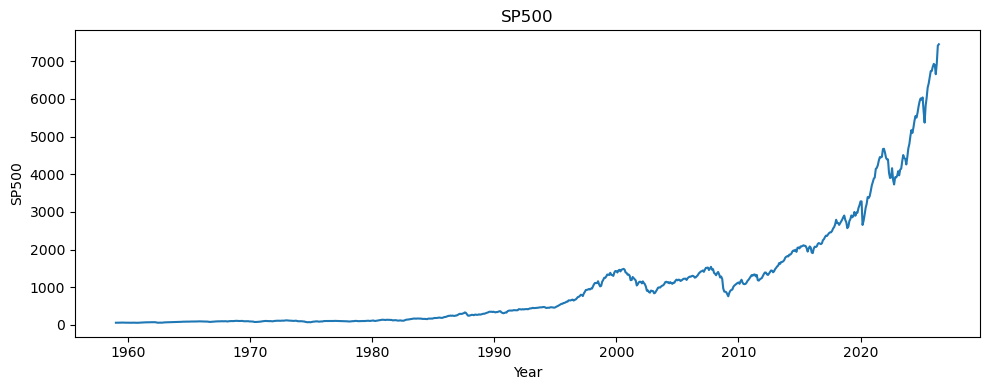

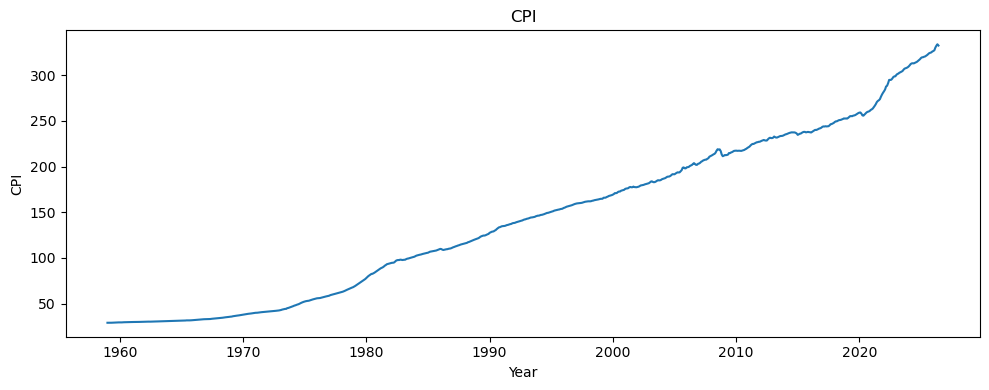

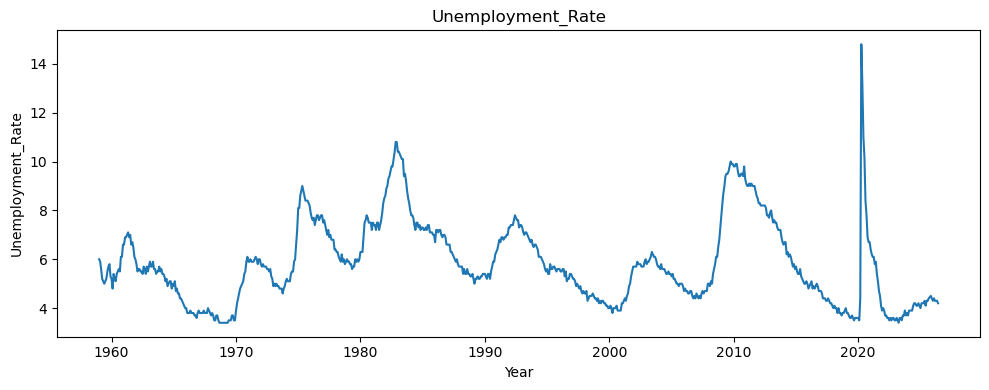

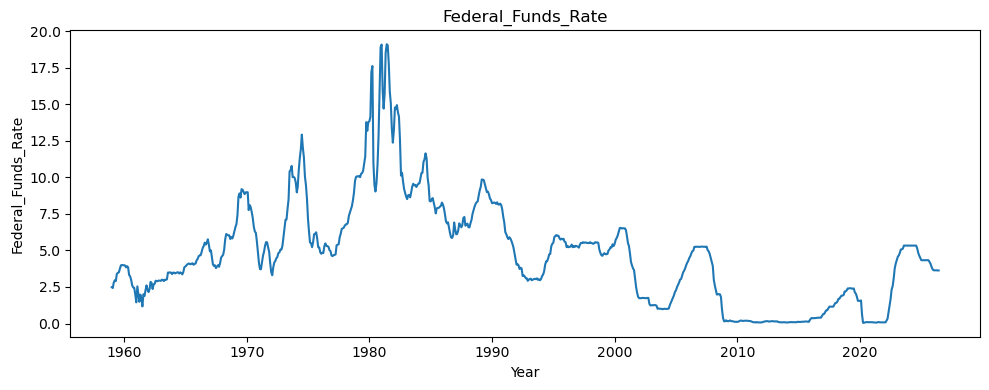

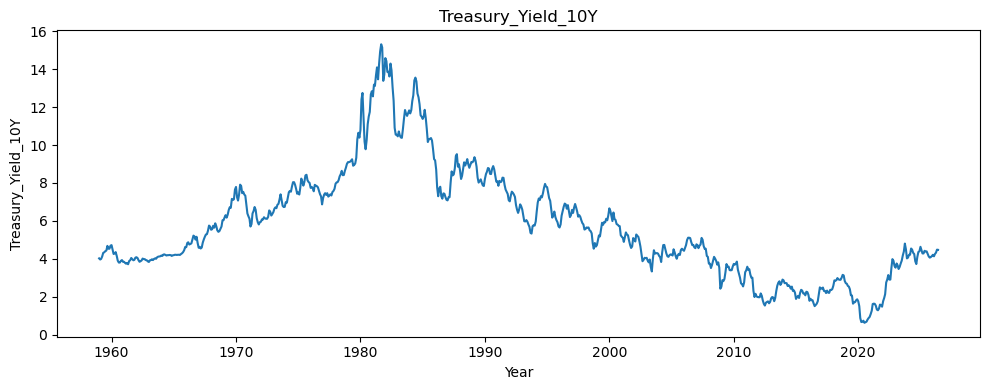

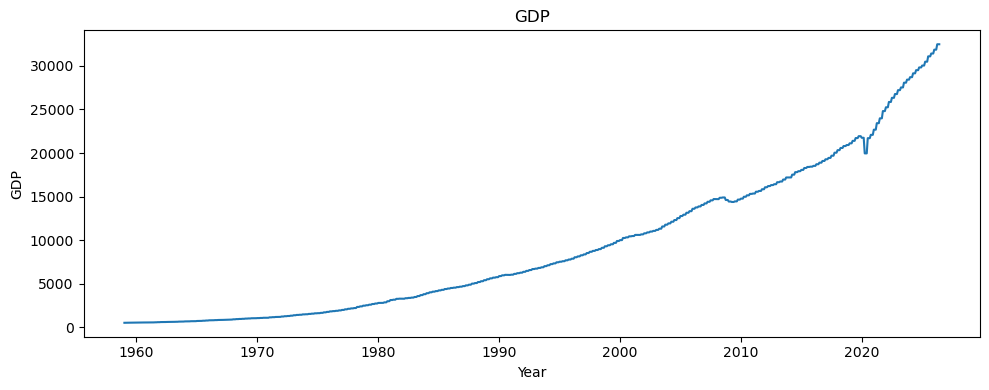

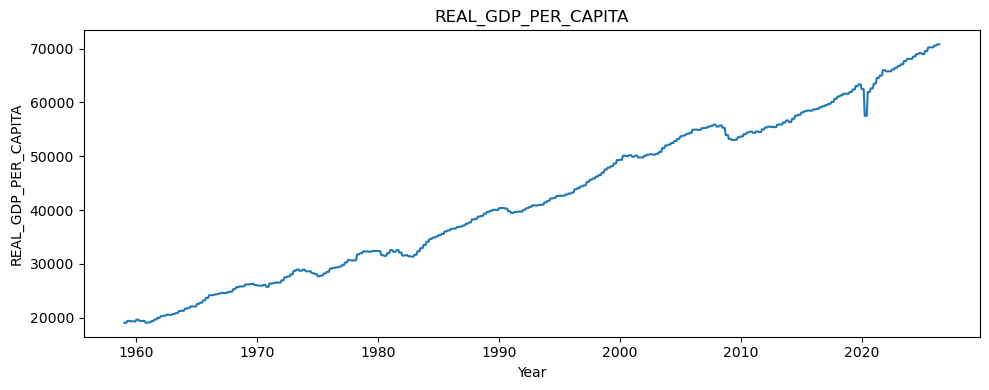

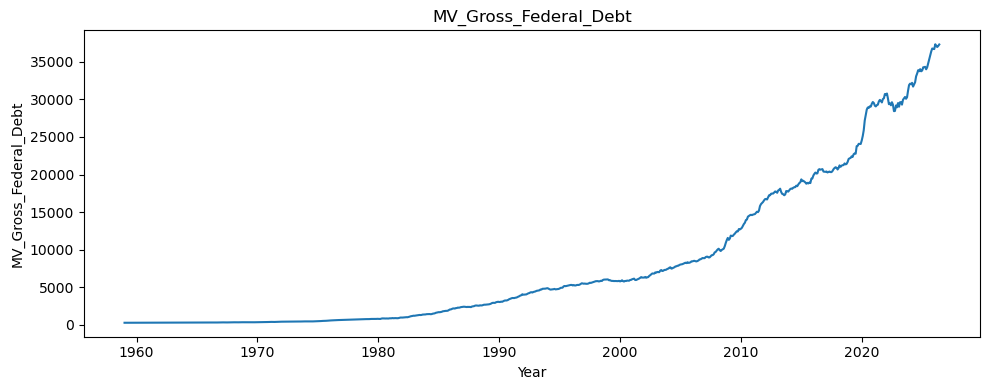

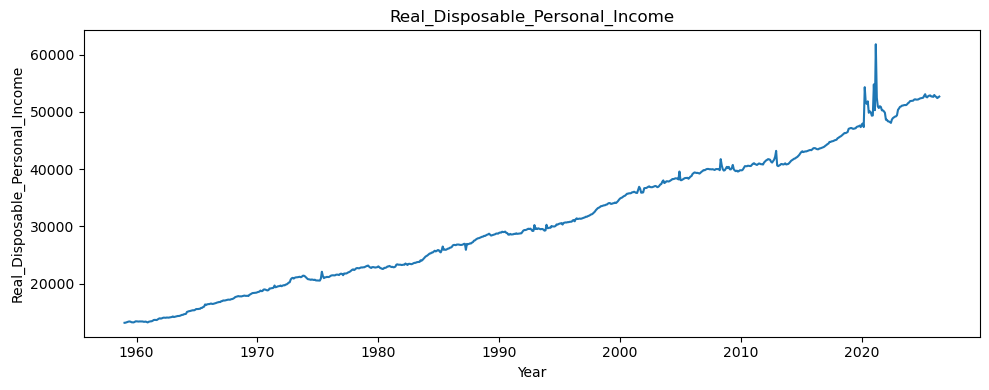

In [1077]:
raw_features = final_data.columns.drop("Date")

for col in raw_features:
    plt.figure(figsize=(10, 4))

    sns.lineplot(data=final_data, x="Date", y=col)

    plt.title(col)
    plt.xlabel("Year")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

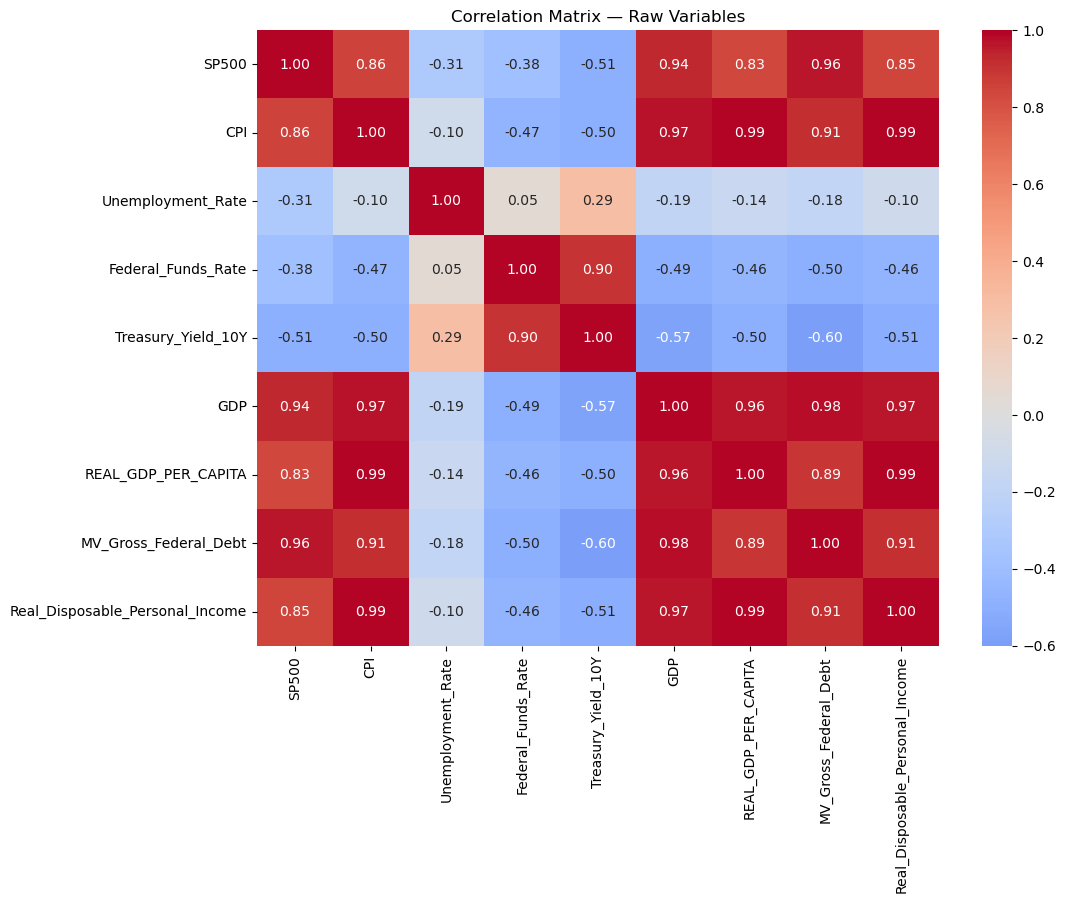

In [1078]:
plt.figure(figsize=(11, 8))

corr_raw = final_data[raw_features].corr()

sns.heatmap(
    corr_raw,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix — Raw Variables")
plt.show()

<h4>Correlation Heatmap – Key Findings</h4>

The S&P 500 has strong positive correlations with federal debt (0.96), GDP (0.94), and CPI (0.86). I will use returns and growth rates to reduce the influence of these trends.

<h2>8. Feature Engineering</h2>

Several raw variables have strong historical trends. I created returns, growth rates, interest-rate changes, and market volatility measures to better compare economic conditions across time.

In [1079]:
model_data = final_data.copy()

<h3>(i) S&P 500 Monthly Return</h3>
Measures the percentage change in the S&P 500 from the previous month.

In [1080]:
model_data["SP500_Monthly_Return"] = (model_data["SP500"].pct_change(fill_method=None) * 100)

<h3>(ii) S&P 500 12-Month Return</h3>
Measures stock market performance over the previous year.

In [1081]:
model_data["SP500_12M_Return"] = (model_data["SP500"].pct_change(12, fill_method=None) * 100)

<h3>(iii) S&P 500 6-Month Volatility</h3>
Measures variation in monthly market returns over the previous six months.

In [1082]:
model_data["SP500_Volatility_6M"] = (model_data["SP500_Monthly_Return"].rolling(6).std())

<h3>(iv) Year-over-Year Inflation</h3>
Measures the percentage change in CPI compared with the same month last year.

In [1083]:
model_data["Inflation_YoY"] = (model_data["CPI"].pct_change(12, fill_method=None) * 100)

<h3>(v) 12-Month Change in Unemployment</h3>
Measures the change in unemployment over 12 months, in percentage points.

In [1084]:
model_data["Unemployment_Change_12M"] = (model_data["Unemployment_Rate"].diff(12))

<h3>(vi) 12-Month Change in Federal Funds Rate</h3>
Measures the change in the federal funds rate over 12 months, in percentage points.

In [1085]:
model_data["Fed_Funds_Change_12M"] = (model_data["Federal_Funds_Rate"].diff(12))

<h3>(vii) 12-Month Change in 10-Year Treasury Yield</h3>
Measures the change in the 10-year Treasury yield over 12 months.

In [1086]:
model_data["Treasury_10Y_Change_12M"] = (model_data["Treasury_Yield_10Y"].diff(12))

<h3>(viii) 10-Year Treasury and Federal Funds Rate Spread</h3>
Measures the difference between the 10-year Treasury yield and the Federal Funds Rate.

In [1087]:
model_data["Yield_Spread_10Y_FedFunds"] = (model_data["Treasury_Yield_10Y"] - model_data["Federal_Funds_Rate"])

<h3>(ix) Year-over-Year GDP Growth</h3>
Measures the annual percentage change in nominal GDP.

In [1088]:
model_data["GDP_Growth_YoY"] = (model_data["GDP"].pct_change(12, fill_method=None) * 100)

<h3>(x) Year-over-Year Real GDP per Capita Growth</h3>
Measures the annual percentage change in inflation-adjusted GDP per person.

In [1089]:
model_data["Real_GDP_Per_Capita_Growth_YoY"] = (model_data["REAL_GDP_PER_CAPITA"].pct_change(12, fill_method=None) * 100)

<h3>(xi) Year-over-Year Federal Debt Growth</h3>
Measures the annual percentage change in federal debt.

In [1090]:
model_data["Federal_Debt_Growth_YoY"] = (model_data["MV_Gross_Federal_Debt"].pct_change(12, fill_method=None) * 100)

<h3>(xii) Year-over-Year Real Disposable Income Growth</h3>
Measures the annual percentage change in real disposable personal income.

In [1091]:
model_data["Disposable_Income_Growth_YoY"] = (model_data["Real_Disposable_Personal_Income"].pct_change(12, fill_method=None) * 100)

In [1092]:
model_features = [
    "SP500_Monthly_Return",
    "SP500_12M_Return",
    "SP500_Volatility_6M",
    
    "Inflation_YoY",
    
    "Unemployment_Rate",
    "Unemployment_Change_12M",
    
    "Federal_Funds_Rate",
    "Fed_Funds_Change_12M",
    
    "Treasury_Yield_10Y",
    "Treasury_10Y_Change_12M",
    "Yield_Spread_10Y_FedFunds",
    
    "GDP_Growth_YoY",
    "Real_GDP_Per_Capita_Growth_YoY",
    
    "Federal_Debt_Growth_YoY",
    "Disposable_Income_Growth_YoY"
]

In [1093]:
model_data[model_features].isna().sum()

SP500_Monthly_Return               1
SP500_12M_Return                  12
SP500_Volatility_6M                6
Inflation_YoY                     12
Unemployment_Rate                  0
Unemployment_Change_12M           12
Federal_Funds_Rate                 0
Fed_Funds_Change_12M              12
Treasury_Yield_10Y                 0
Treasury_10Y_Change_12M           12
Yield_Spread_10Y_FedFunds          0
GDP_Growth_YoY                    12
Real_GDP_Per_Capita_Growth_YoY    12
Federal_Debt_Growth_YoY           12
Disposable_Income_Growth_YoY      12
dtype: int64

<h3>Preparing the Modeling Dataset</h3>

Some features require up to 12 months of previous data. I removed rows with missing engineered features before proceeding with PCA and clustering.

In [1094]:
ml_data = (model_data[["Date"] + model_features].dropna().reset_index(drop=True))

In [1095]:
print("Modeling observations:", len(ml_data))
print("Start:", ml_data["Date"].min())
print("End:", ml_data["Date"].max())

ml_data.head()

Modeling observations: 798
Start: 1960-01-01 00:00:00
End: 2026-06-01 00:00:00


,Date,SP500_Monthly_Return,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Unemployment_Change_12M,Federal_Funds_Rate,Fed_Funds_Change_12M,Treasury_Yield_10Y,Treasury_10Y_Change_12M,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY,Real_GDP_Per_Capita_Growth_YoY,Federal_Debt_Growth_YoY,Disposable_Income_Growth_YoY
0,1960-01-01,-1.743989,4.332974,2.372621,1.240951,5.2,-0.8,3.99,1.51,4.72,0.70,0.73,6.332765,3.009296,0.694191,1.933869
1,1960-02-01,-3.877305,1.844075,2.756566,1.413793,4.8,-1.1,3.97,1.54,4.49,0.53,0.52,6.332765,3.009296,0.656216,1.544402
2,1960-03-01,-1.362496,-2.029915,2.379896,1.518813,5.4,-0.2,3.84,1.04,4.25,0.26,0.41,6.332765,3.009296,2.481481,1.002487
3,1960-04-01,1.290440,-2.399299,2.500187,1.932367,5.2,0.0,3.92,0.96,4.28,0.16,0.36,3.525666,-0.015468,1.875690,0.667367
4,1960-05-01,-0.915127,-4.727398,2.478705,1.825069,5.1,0.0,3.85,0.95,4.35,0.04,0.50,3.525666,-0.015468,2.240176,0.276284


In [1096]:
ml_data[model_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SP500_Monthly_Return,798.0,0.67,3.54,-20.39,-1.01,0.99,2.89,12.02
SP500_12M_Return,798.0,8.64,15.51,-42.51,-0.45,10.18,18.99,52.65
SP500_Volatility_6M,798.0,3.01,1.54,0.43,1.98,2.67,3.73,9.91
Inflation_YoY,798.0,3.74,2.78,-1.96,1.89,3.01,4.64,14.59
Unemployment_Rate,798.0,5.85,1.69,3.40,4.60,5.60,6.90,14.80
Unemployment_Change_12M,798.0,-0.02,1.35,-8.70,-0.60,-0.30,0.30,11.10
Federal_Funds_Rate,798.0,4.78,3.60,0.05,2.00,4.66,6.49,19.10
Fed_Funds_Change_12M,798.0,0.01,2.08,-7.70,-0.85,0.03,0.97,10.01
Treasury_Yield_10Y,798.0,5.76,2.91,0.62,3.88,5.22,7.46,15.32
Treasury_10Y_Change_12M,798.0,-0.00,1.11,-4.24,-0.64,0.06,0.64,4.03


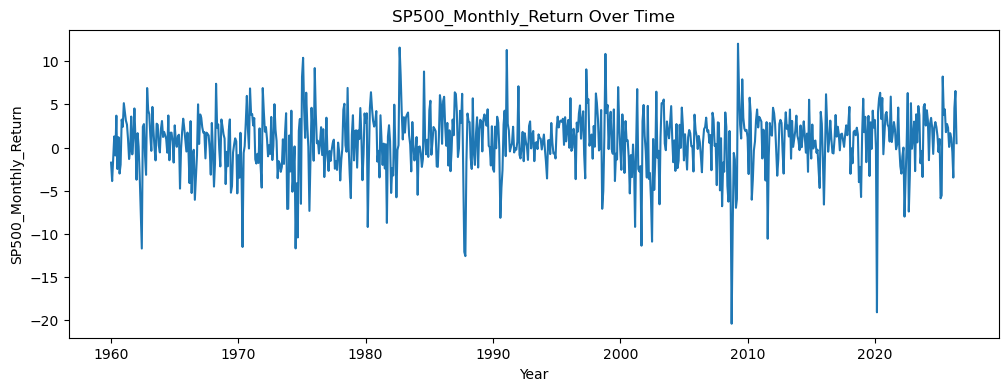

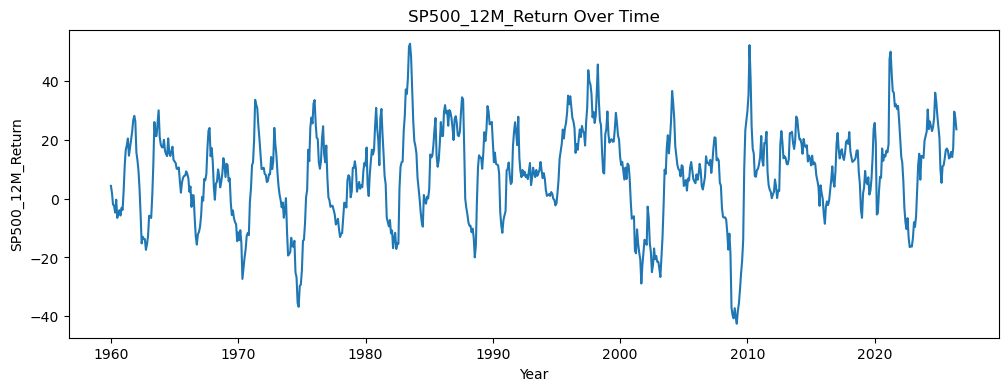

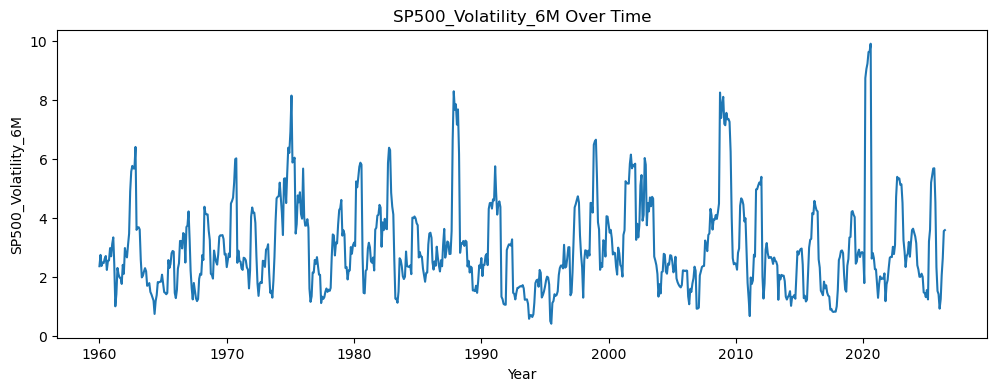

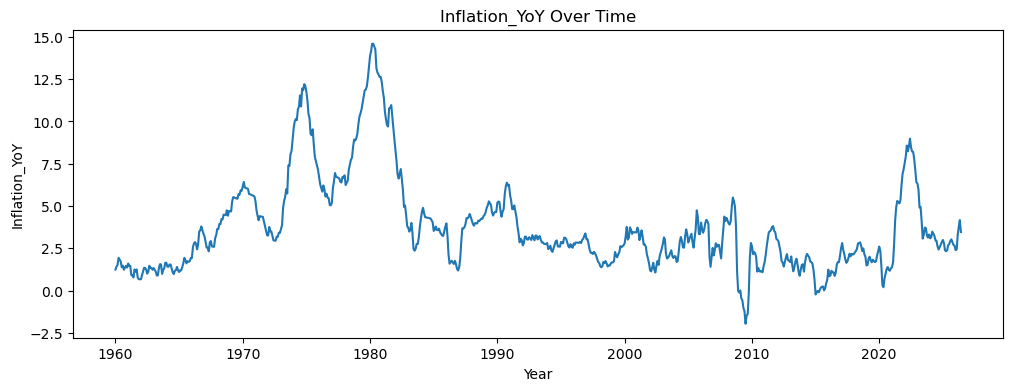

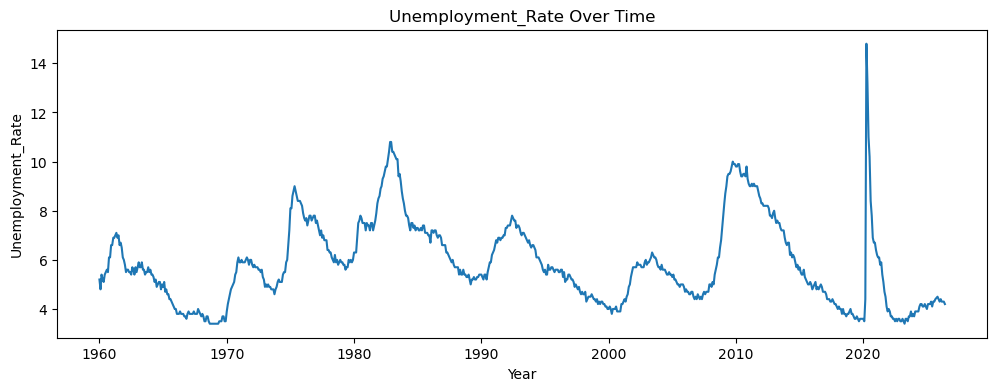

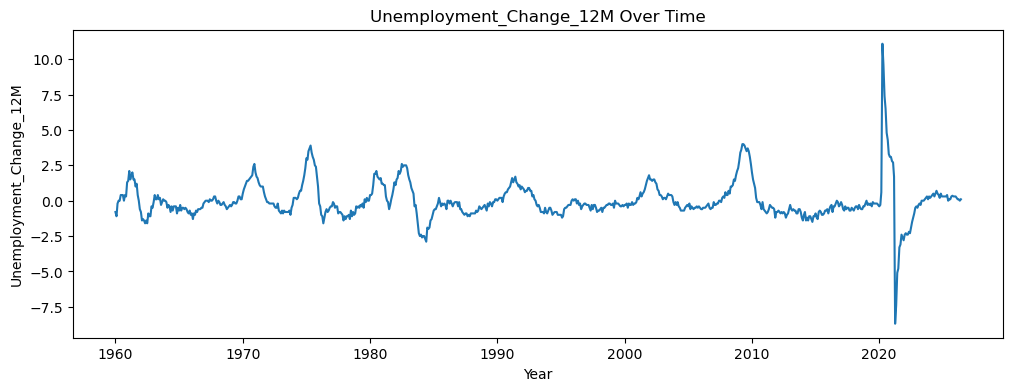

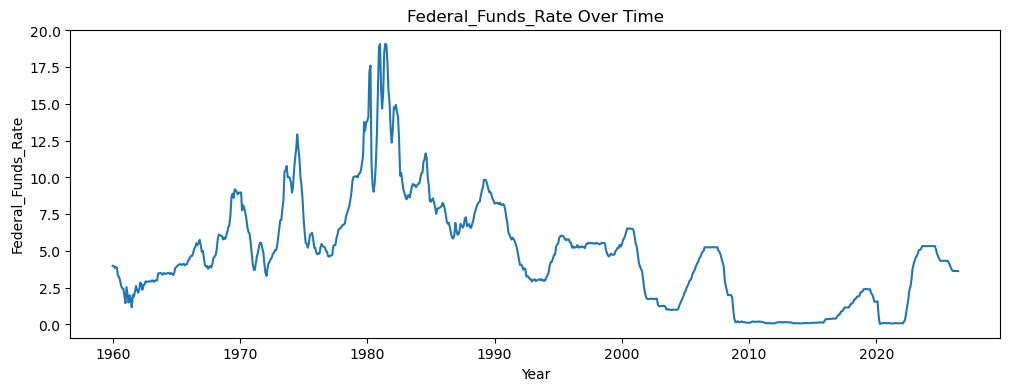

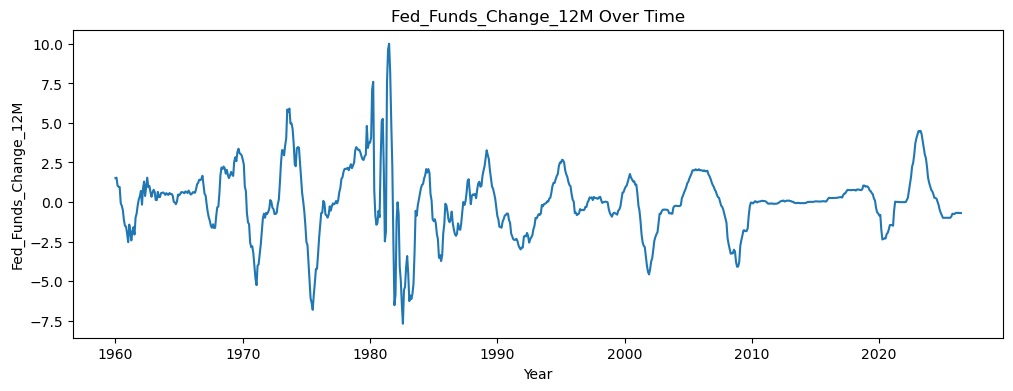

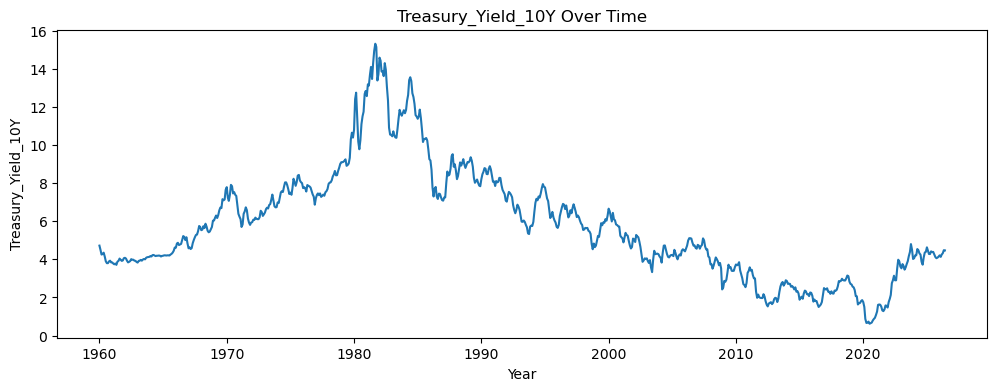

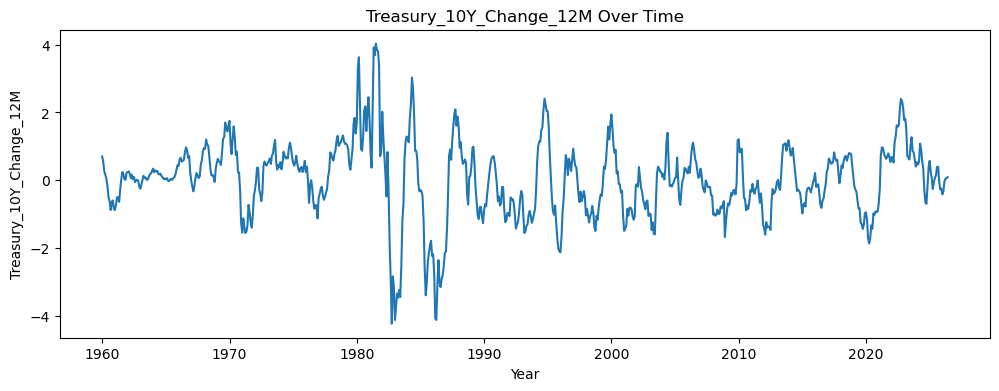

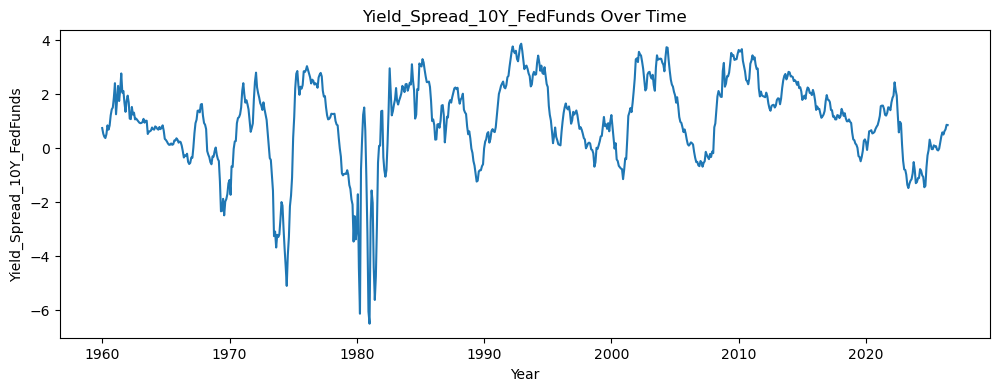

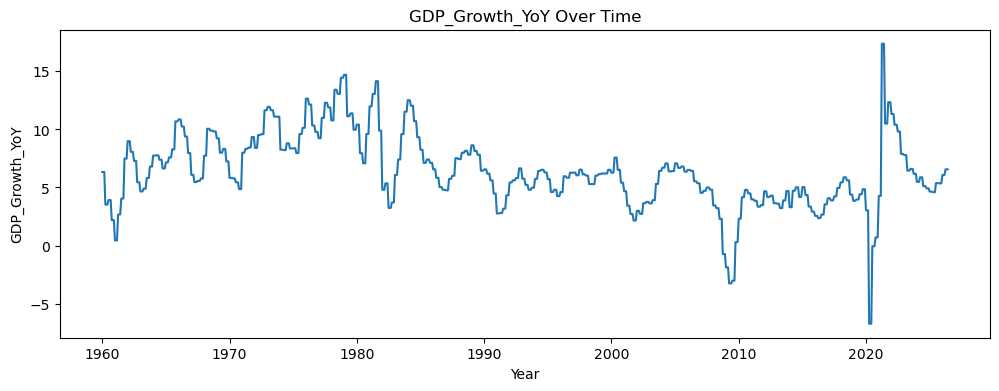

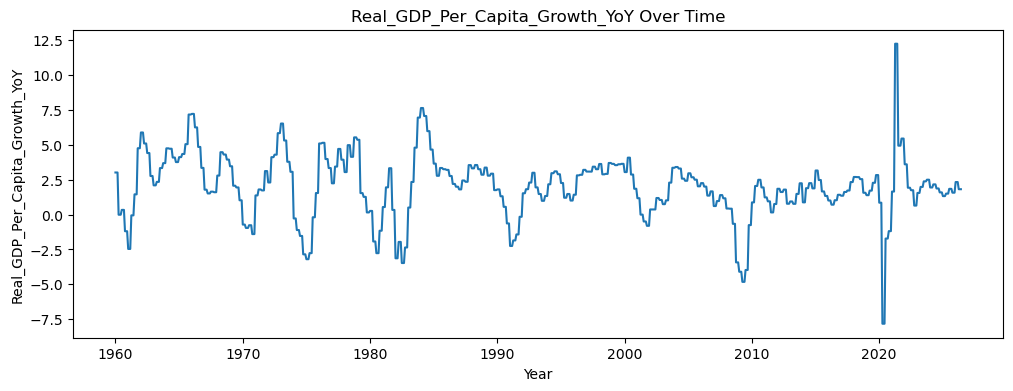

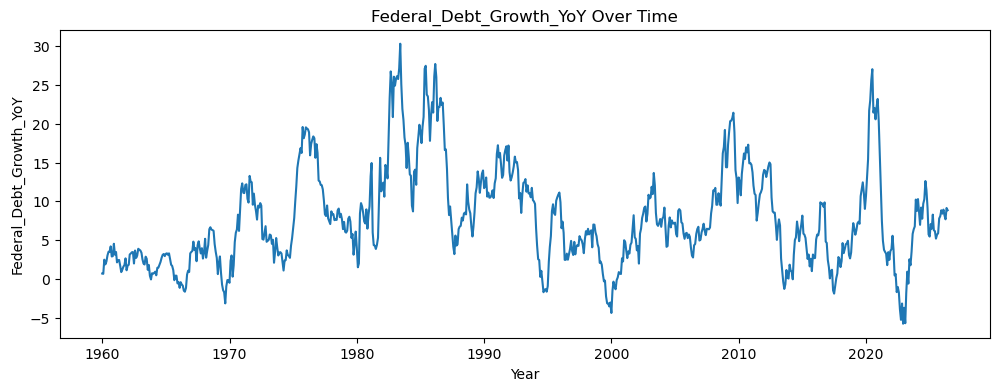

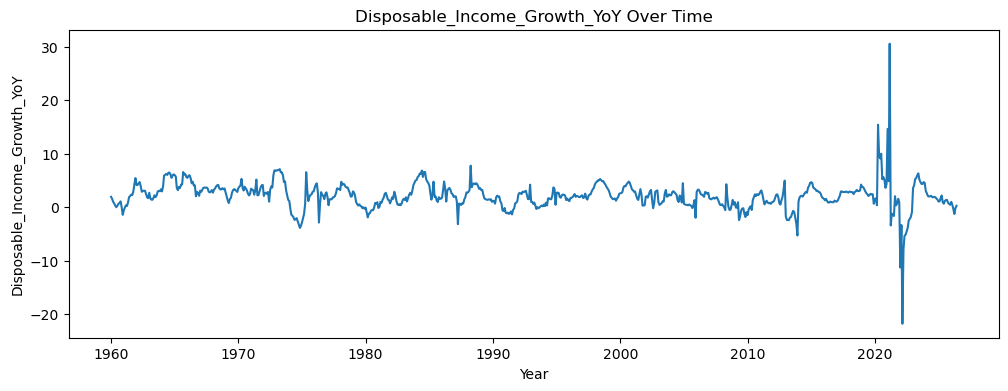

In [1097]:
for col in model_features:
    
    plt.figure(figsize=(12, 4))
    
    sns.lineplot(
        data=ml_data,
        x="Date",
        y=col
    )
    
    plt.title(f"{col} Over Time")
    plt.xlabel("Year")
    plt.ylabel(col)
    plt.show()

<h3>Correlation of Engineered Features</h3>
I reviewed correlations between the engineered features to identify variables that may contain similar information before PCA.

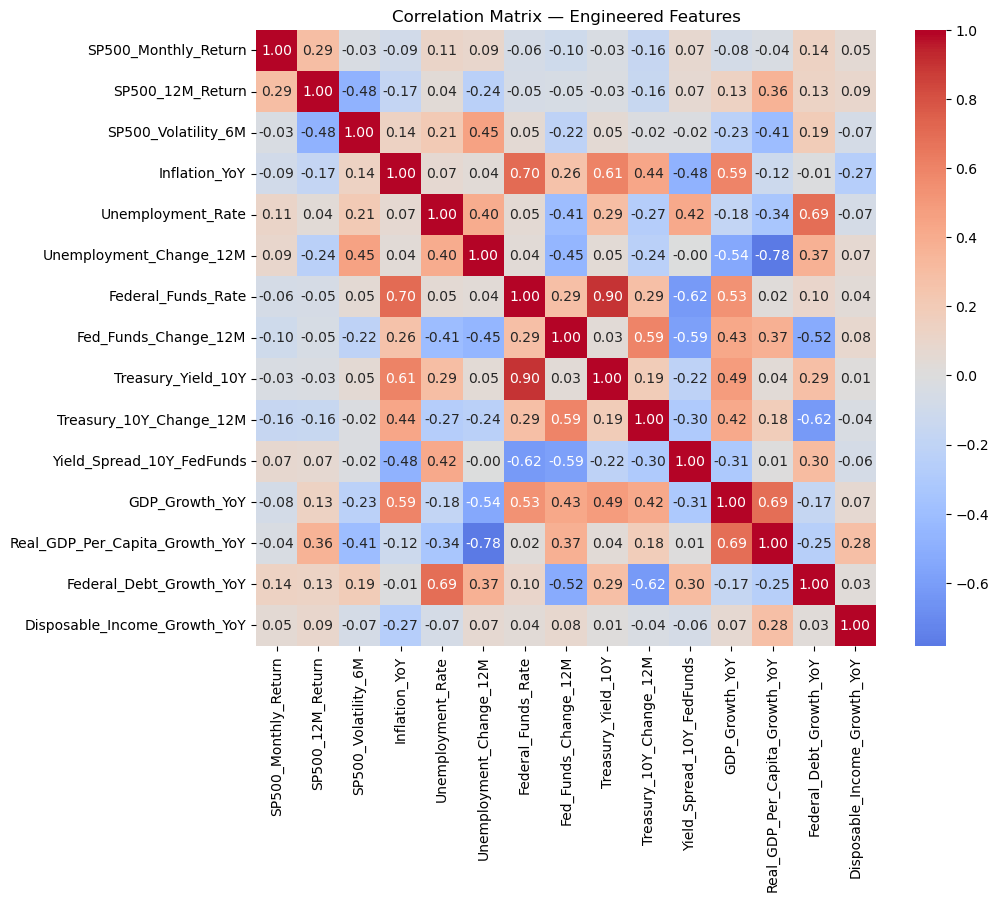

In [1098]:
plt.figure(figsize=(10, 8))

corr_engineered = (
    ml_data[model_features]
    .corr()
)

sns.heatmap(
    corr_engineered,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix — Engineered Features")
plt.show()

<h4>Correlation Analysis – Engineered Features</h4>
The engineered features have weaker correlations with monthly S&P 500 returns. However, the Federal Funds Rate and 10-Year Treasury Yield remain strongly correlated (0.90), as do unemployment change and real GDP per capita growth (-0.78). PCA may help summarize some of these relationships.

<h3>Distribution and Outlier Review</h3>

To review the distributions of selected features to identify extreme observations, these values are retained because they may represent important economic events.

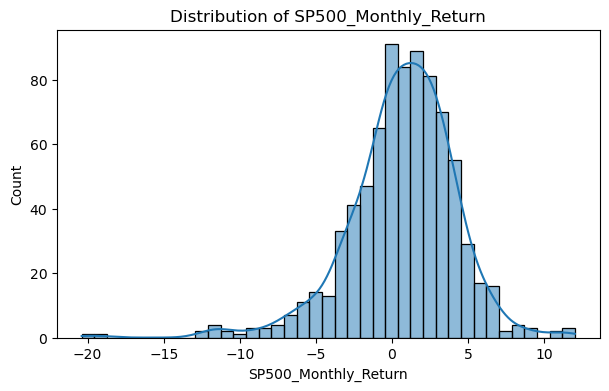

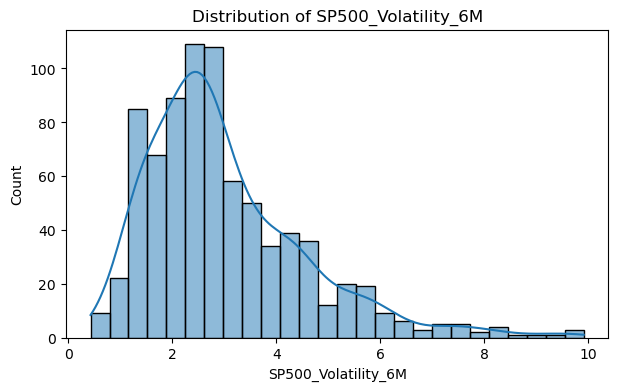

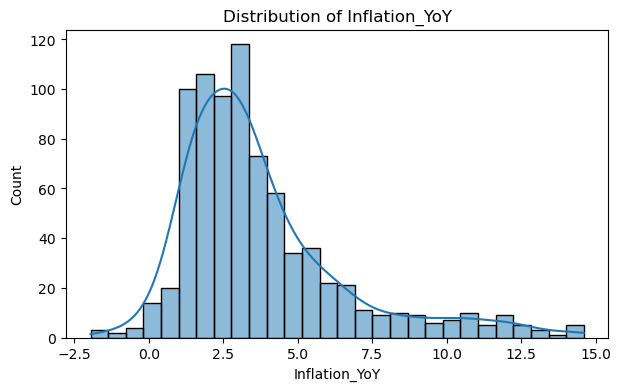

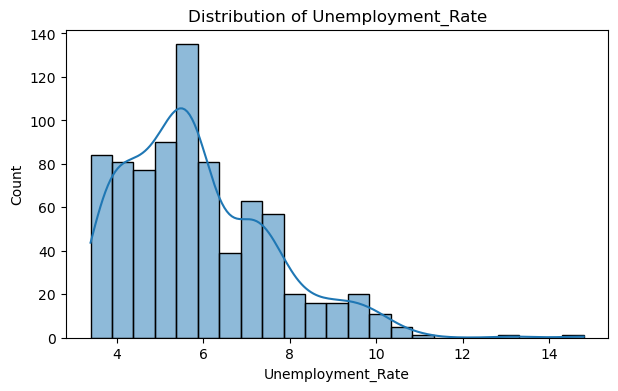

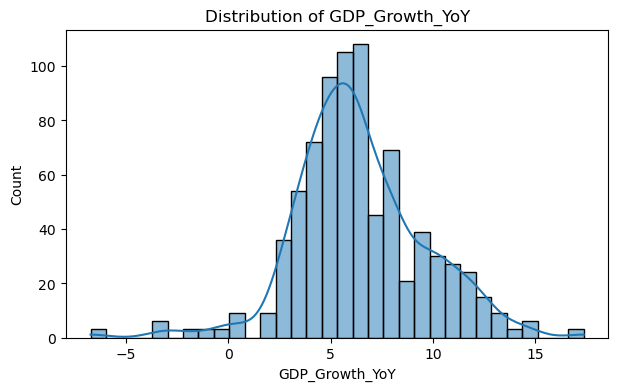

In [1099]:
features_to_plot = [
    "SP500_Monthly_Return",
    "SP500_Volatility_6M",
    "Inflation_YoY",
    "Unemployment_Rate",
    "GDP_Growth_YoY"
]

for col in features_to_plot:
    
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        ml_data[col],
        kde=True
    )
    
    plt.title(f"Distribution of {col}")
    plt.show()

<h2>9. Standardization</h2>

The features have different units and scales. I divided the data chronologically into training and test periods, then fitted StandardScaler using only the training observations. The same scaling parameters are applied to the test period.

In [1100]:
ml_data = ml_data.sort_values("Date").reset_index(drop=True) # Sort observations by date

split = int(len(ml_data) * 0.8) # Chronological 80/20 split

train_data = ml_data.iloc[:split].copy()
test_data = ml_data.iloc[split:].copy()

# Select modeling features
X_train = train_data[model_features]
X_test = test_data[model_features]

scaler = StandardScaler() # Fit scaler on training data only

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Testing:", test_data["Date"].min(), "to", test_data["Date"].max())

Training: 1960-01-01 00:00:00 to 2013-02-01 00:00:00
Testing: 2013-03-01 00:00:00 to 2026-06-01 00:00:00


In [1101]:
# Create DataFrames for scaled features
train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=model_features,
    index=train_data.index
)

test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=model_features,
    index=test_data.index
)

train_scaled.head()

,SP500_Monthly_Return,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Unemployment_Change_12M,Federal_Funds_Rate,Fed_Funds_Change_12M,Treasury_Yield_10Y,Treasury_10Y_Change_12M,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY,Real_GDP_Per_Capita_Growth_YoY,Federal_Debt_Growth_YoY,Disposable_Income_Growth_YoY
0,-0.645148,-0.196650,-0.462895,-0.960770,-0.549518,-0.789754,-0.434511,0.703850,-0.669073,0.639944,-0.158089,-0.13376,0.424786,-1.195373,-0.129578
1,-1.238582,-0.351978,-0.203954,-0.900643,-0.797156,-1.069161,-0.440158,0.717304,-0.754238,0.494440,-0.282026,-0.13376,0.424786,-1.201332,-0.332900
2,-0.539026,-0.593747,-0.457989,-0.864110,-0.425700,-0.230941,-0.476860,0.493057,-0.843107,0.263345,-0.346946,-0.13376,0.424786,-0.914912,-0.615807
3,0.198953,-0.616800,-0.376861,-0.720245,-0.549518,-0.044670,-0.454274,0.457177,-0.831998,0.177755,-0.376454,-1.06238,-0.895810,-1.009973,-0.790758
4,-0.414579,-0.762093,-0.391350,-0.757571,-0.611428,-0.044670,-0.474037,0.452692,-0.806078,0.075046,-0.293830,-1.06238,-0.895810,-0.952777,-0.994923


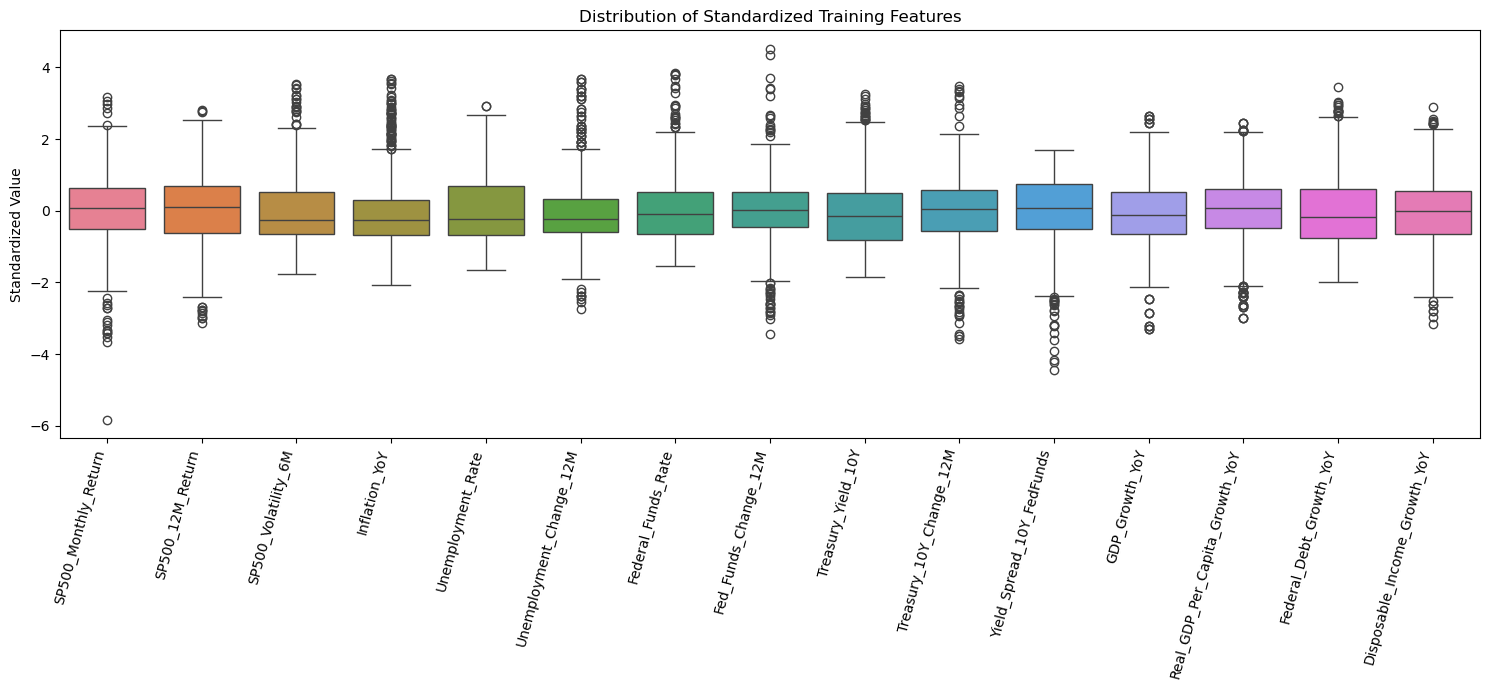

In [1102]:
plt.figure(figsize=(15, 7))

sns.boxplot(data=train_scaled)

plt.xticks(rotation=75, ha="right")
plt.title("Distribution of Standardized Training Features")
plt.ylabel("Standardized Value")

plt.tight_layout()
plt.show()

<h3>Data Ready for Machine Learning Modeling</h3>

The modeling features have been standardized using the training period. PCA and K-Means will also be fitted using training observations before applying the models to the test period.

<h2>10. Principal Component Analysis (PCA)</h2>

Several engineered features are correlated. I used PCA to reduce the number of variables while retaining most of the variation in the training data.

In [1103]:
# Fit PCA on training data
pca = PCA()

pca.fit(train_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

In [1104]:
# Create a table showing the variance explained by each component
pca_results = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": cumulative_variance
})

pca_results.round(3)

,Component,Explained_Variance,Cumulative_Variance
0,1,0.296,0.296
1,2,0.215,0.512
2,3,0.150,0.662
3,4,0.078,0.739
4,5,0.059,0.798
5,6,0.054,0.852
6,7,0.041,0.893
7,8,0.030,0.924
8,9,0.028,0.951
9,10,0.024,0.976


<h3>Selecting the Number of Principal Components</h3>

I used cumulative explained variance from the training data to decide how many principal components to retain.

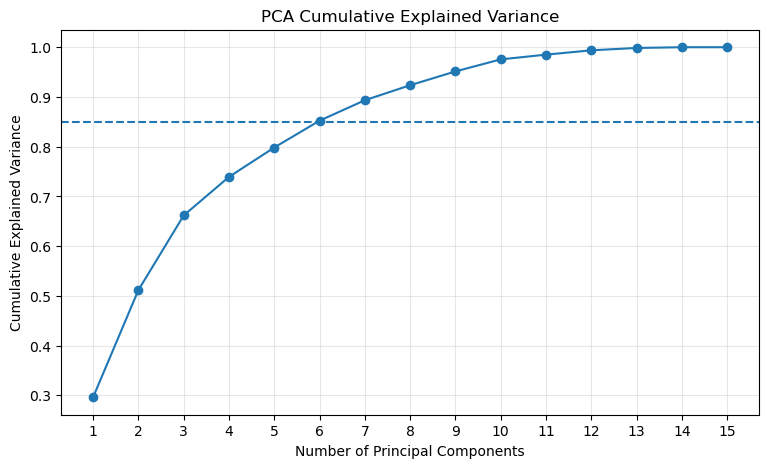

In [1105]:
# Plot cumulative explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

# Reference line for 85% explained variance
plt.axhline(y=0.85, linestyle="--")

plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(alpha=0.3)

plt.show()

In [1106]:
print("Variance explained by 6 PCs:",
      round(cumulative_variance[5] * 100, 2), "%")

Variance explained by 6 PCs: 85.22 %


<h3>PCA Selection</h3>

I selected six principal components because they explain approximately 85% of the variation in the standardized training data. This reduces the number of variables from 15 to 6 while retaining most of the information for clustering.

In [1107]:
# Fit final PCA on training data only
pca_final = PCA(n_components=6)

X_train_pca = pca_final.fit_transform(train_scaled)

# Apply the same PCA to test data
X_test_pca = pca_final.transform(test_scaled)

In [1108]:
# Create PCA DataFrames
pca_columns = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"]

train_pca = pd.DataFrame(
    X_train_pca,
    columns=pca_columns,
    index=train_data.index
)

test_pca = pd.DataFrame(
    X_test_pca,
    columns=pca_columns,
    index=test_data.index
)

train_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6
0,0.853271,-1.503374,-1.297937,-0.026203,-0.717604,0.309526
1,0.950466,-1.474355,-1.647195,-0.366635,-1.037717,-0.018277
2,0.314183,-1.082051,-1.400264,0.111965,-0.721614,0.101019
3,-0.515206,-0.546520,-1.901040,1.068502,-0.387215,0.140624
4,-0.580450,-0.489778,-2.072558,0.724648,-0.856102,-0.082998


<h3>Understanding the Principal Components</h3>

PCA loadings show which original features contribute most to each component.

In [1109]:
# Show how the original features contribute to each component
loadings = pd.DataFrame(
    pca_final.components_.T,
    index=model_features,
    columns= ("PC1", "PC2", "PC3", "PC4", "PC5", "PC6")
)

loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6
SP500_Monthly_Return,-0.07,-0.04,0.22,0.53,0.66,0.35
SP500_12M_Return,0.04,-0.18,0.42,0.44,-0.15,0.01
SP500_Volatility_6M,-0.14,0.25,-0.23,-0.35,0.48,0.07
Inflation_YoY,0.22,0.44,0.03,0.04,-0.04,0.09
Unemployment_Rate,-0.24,0.22,0.34,-0.15,-0.21,0.38
Unemployment_Change_12M,-0.29,0.31,-0.14,0.14,0.14,-0.11
Federal_Funds_Rate,0.29,0.38,0.17,0.06,0.06,-0.23
Fed_Funds_Change_12M,0.38,-0.04,-0.16,0.14,-0.17,0.20
Treasury_Yield_10Y,0.19,0.37,0.33,-0.12,0.05,-0.04
Treasury_10Y_Change_12M,0.31,0.12,-0.23,-0.09,-0.02,0.58


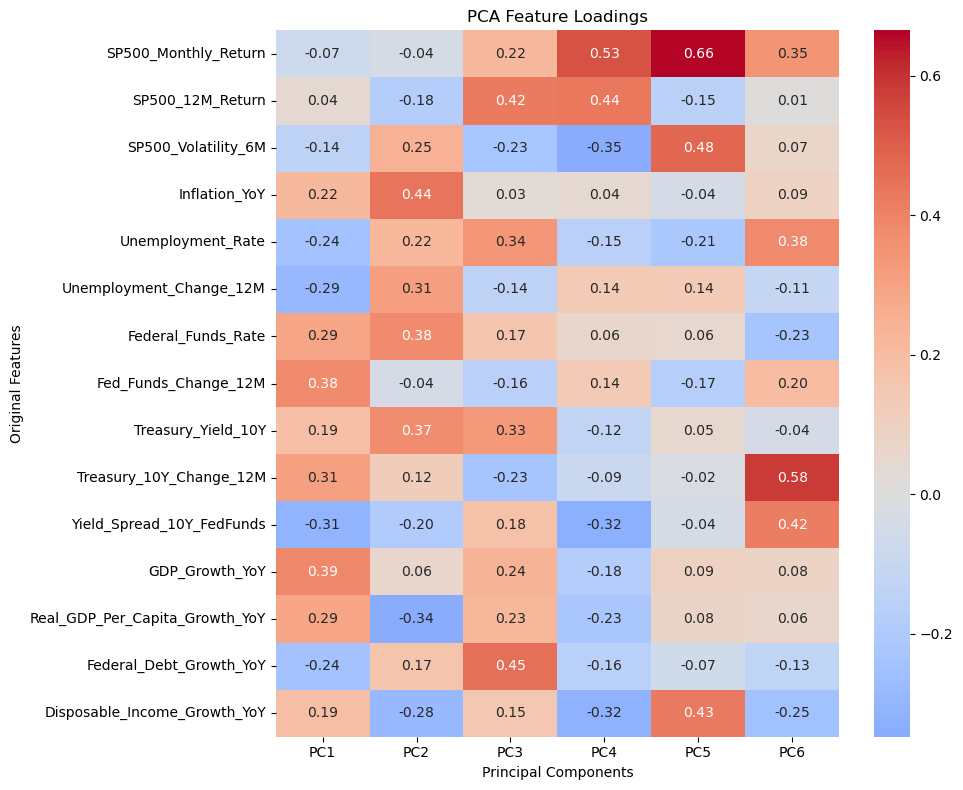

In [1110]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("PCA Feature Loadings")
plt.xlabel("Principal Components")
plt.ylabel("Original Features")

plt.tight_layout()
plt.show()

<h4>PCA Feature Loadings – Interpretation</h4>
The PCA heatmap shows that the components capture different combinations of economic and market variables. These six components will be used for K-Means clustering to identify months with similar economic and market conditions.

- PC1: Mainly reflects GDP growth and changes in interest rates.
- PC2: Captures inflation and interest-rate conditions.
- PC3: Combines federal debt growth, annual S&P 500 returns, and unemployment.
- PC4: Primarily reflects stock market returns and volatility.
- PC5: Captures monthly market returns, volatility, and disposable income growth.
- PC6: Mainly reflects changes in Treasury yields, the yield spread, and unemployment.

<h2>11. K-Means Clustering</h2>

Used K-Means to group months with similar economic and market conditions. The model is fitted using the training-period PCA components. I compared different cluster counts using the Elbow Method and Silhouette Score.

In [1111]:
#warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

# Test different numbers of clusters
k_values = range(2, 11)

inertia = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(train_pca)

    inertia.append(kmeans.inertia_)

<h3>Elbow Method</h3>

The Elbow Method compares how within-cluster variation changes as the number of clusters increases.

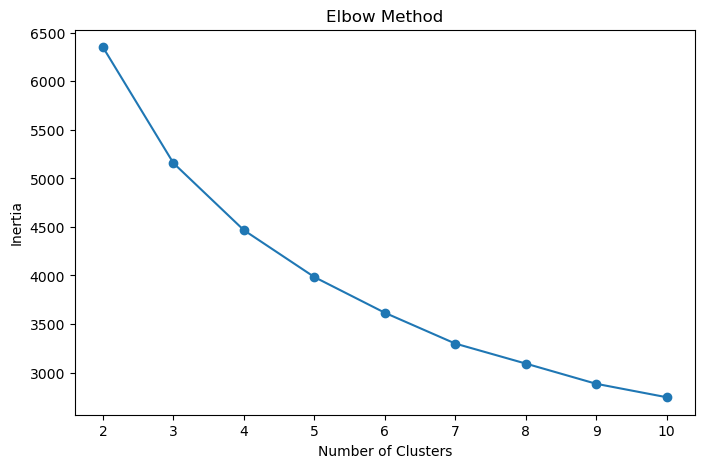

In [1112]:
# Plot the Elbow Method results
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

<h3>Silhouette Score</h3>

The Silhouette Score measures how well observations fit within their assigned clusters compared with other clusters.

In [1113]:
# Calculate silhouette score for each number of clusters
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(train_pca)

    score = silhouette_score(train_pca, labels)

    silhouette_scores.append(score)

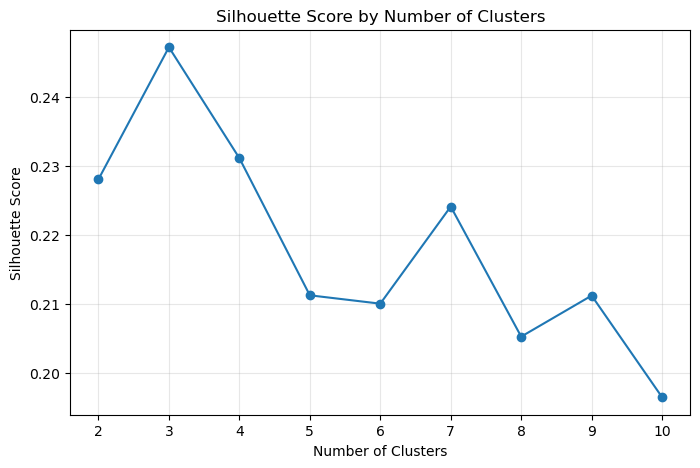

In [1114]:
# Plot silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [1115]:
# Compare the results
cluster_results = pd.DataFrame({
    "Number_of_Clusters": list(k_values),
    "Inertia": inertia,
    "Silhouette_Score": silhouette_scores
})

cluster_results.round(3)

,Number_of_Clusters,Inertia,Silhouette_Score
0,2,6351.813,0.228
1,3,5157.952,0.247
2,4,4466.811,0.231
3,5,3983.902,0.211
4,6,3615.921,0.210
5,7,3298.351,0.224
6,8,3092.351,0.205
7,9,2883.863,0.211
8,10,2745.394,0.196


<h3>Selecting number of clusters</h3>

The highest silhouette score is approximately 0.247 for three clusters, compared with 0.231 for four clusters. I selected four clusters because the additional group helps distinguish the high-inflation and monetary-tightening conditions of the 1970s and early 1980s. This provides a more detailed economic interpretation, although the silhouette score is slightly lower.

In [1116]:
# Fit K-Means on training PCA components
final_k = 4

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

train_clusters = kmeans_final.fit_predict(train_pca)

# Assign test observations to the existing clusters
test_clusters = kmeans_final.predict(test_pca)

In [1117]:
# Assign cluster labels
train_data["Cluster"] = train_clusters
test_data["Cluster"] = test_clusters

# Identify training and test observations
train_data["Dataset"] = "Train"
test_data["Dataset"] = "Test"

# Combine datasets for historical analysis
ml_data = pd.concat(
    [train_data, test_data]
).sort_values("Date").reset_index(drop=True)

ml_data[["Date", "Dataset", "Cluster"]].head()

,Date,Dataset,Cluster
0,1960-01-01,Train,1
1,1960-02-01,Train,1
2,1960-03-01,Train,1
3,1960-04-01,Train,1
4,1960-05-01,Train,1


In [1118]:
ml_data[["Date", "Dataset", "Cluster"]].tail()

,Date,Dataset,Cluster
793,2026-02-01,Test,1
794,2026-03-01,Test,1
795,2026-04-01,Test,1
796,2026-05-01,Test,1
797,2026-06-01,Test,1


In [1119]:
# Count the number of months in each cluster
cluster_counts = ml_data["Cluster"].value_counts().sort_index()

print(cluster_counts)

Cluster
0    185
1    437
2     59
3    117
Name: count, dtype: int64


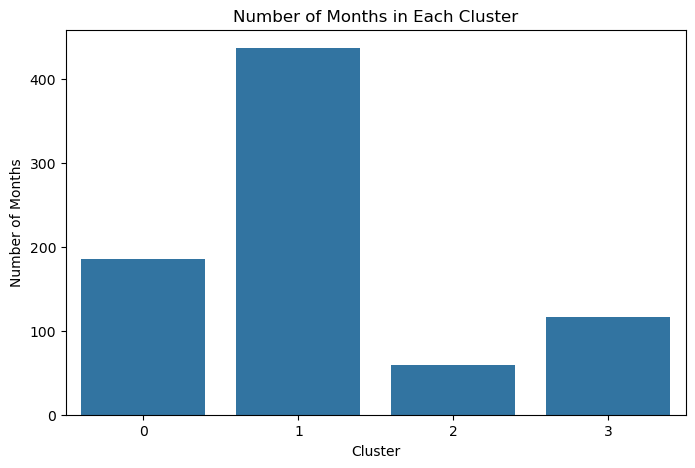

In [1120]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ml_data,
    x="Cluster",
    order=sorted(ml_data["Cluster"].unique())
)

plt.title("Number of Months in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Months")

plt.show()

<h3>Cluster Size</h3>

<p>
The number of months assigned to each cluster is reviewed to understand how
frequently each type of economic environment occurred in the historical data.
Very small clusters may represent unusual economic conditions or extreme events.
</p>

In [1121]:
# Calculate the average feature value for each cluster
cluster_profile = (
    train_data
    .groupby("Cluster")[model_features]
    .mean()
    .round(2)
)

cluster_profile

,SP500_Monthly_Return,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Unemployment_Change_12M,Federal_Funds_Rate,Fed_Funds_Change_12M,Treasury_Yield_10Y,Treasury_10Y_Change_12M,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY,Real_GDP_Per_Capita_Growth_YoY,Federal_Debt_Growth_YoY,Disposable_Income_Growth_YoY
Cluster,,,,,,,,,,,,,,,
0,1.22,18.57,2.43,3.26,7.37,-0.01,4.35,-1.21,6.52,-0.97,2.17,6.36,2.18,14.31,1.86
1,0.52,8.54,2.70,3.27,5.01,-0.51,5.48,0.93,6.09,0.35,0.61,7.56,3.32,4.45,3.19
2,-0.61,-0.17,3.79,10.90,6.76,0.62,12.81,2.11,10.77,1.42,-2.05,9.94,0.19,6.77,0.26
3,0.34,-9.83,4.77,3.52,6.84,1.51,3.50,-2.37,5.45,-0.55,1.95,3.06,-1.04,10.87,0.78


<h3>Understanding the Clusters</h3>

<p>
K-Means assigns a cluster number to each month, but the cluster numbers do not
have an economic meaning by themselves.
</p>

<p>
To understand each cluster, the average values of the original engineered
features are calculated for each group. These averages help describe the market,
inflation, employment, interest-rate, growth, and fiscal conditions associated
with each cluster.
</p>

In [1122]:
# Add cluster labels to standardized training data
scaled_with_clusters = train_scaled.copy()

scaled_with_clusters["Cluster"] = train_clusters


# Average standardized features by cluster
cluster_heatmap = (
    scaled_with_clusters
    .groupby("Cluster")
    .mean()
)


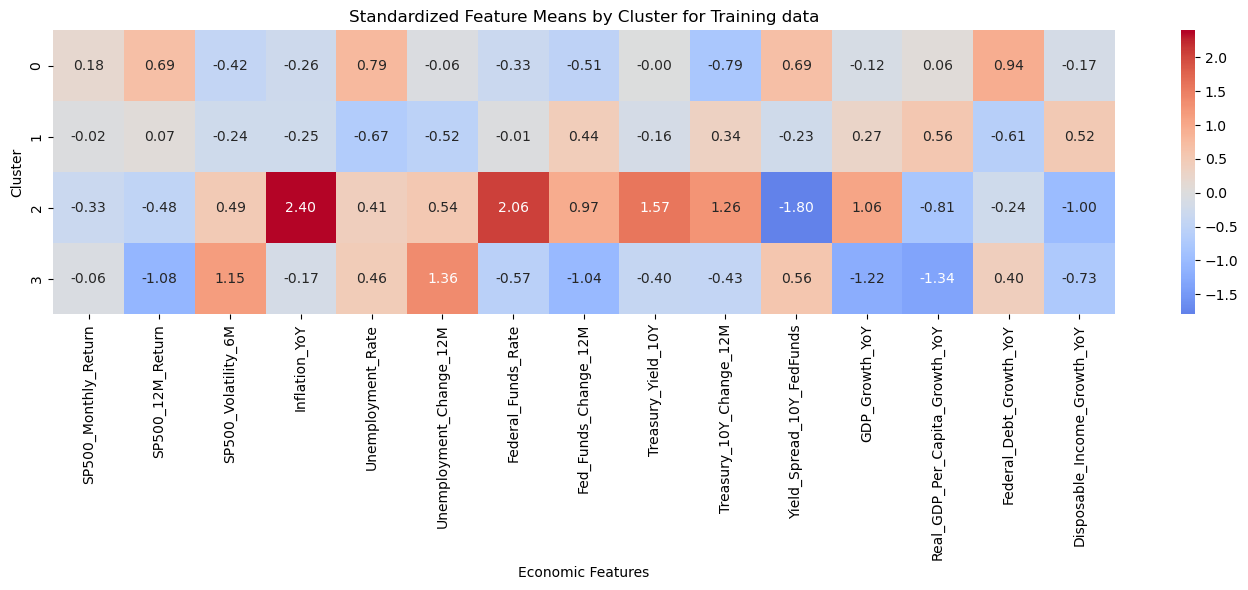

In [1123]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    cluster_heatmap,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Standardized Feature Means by Cluster for Training data")
plt.xlabel("Economic Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

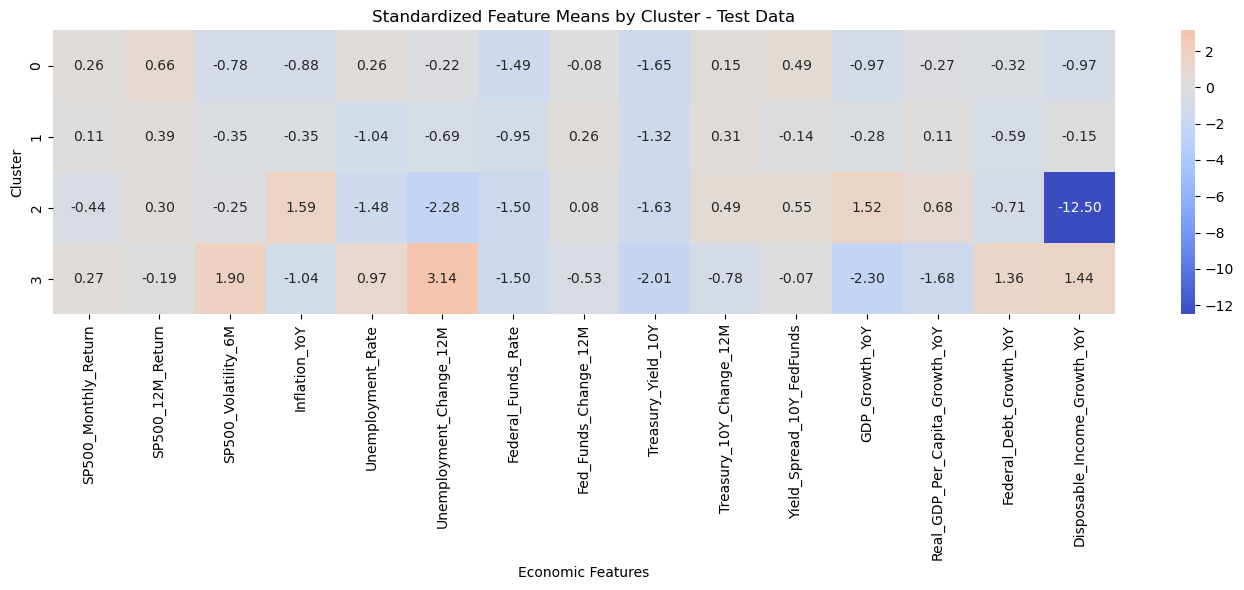

In [1124]:
# Add cluster labels to standardized test data
test_scaled_with_clusters = test_scaled.copy()
test_scaled_with_clusters["Cluster"] = test_clusters

test_cluster_heatmap = test_scaled_with_clusters.groupby("Cluster").mean() # Calculate average standardized features by cluster

# Create heatmap
plt.figure(figsize=(14, 6))

sns.heatmap(
    test_cluster_heatmap,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Standardized Feature Means by Cluster - Test Data")
plt.xlabel("Economic Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

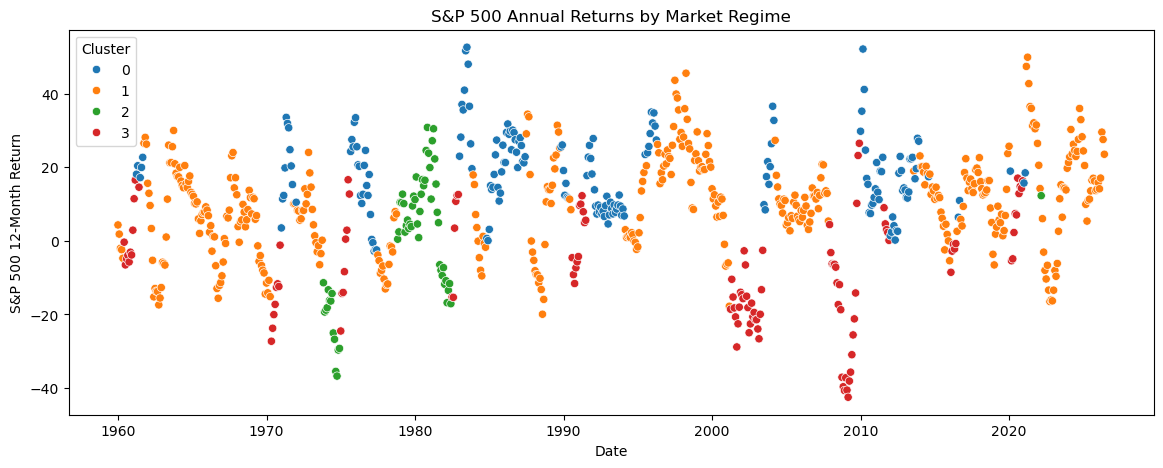

In [1125]:
plt.figure(figsize=(14, 5))

sns.scatterplot(
    data=ml_data,
    x="Date",
    y="SP500_12M_Return",
    hue="Cluster",
    palette="tab10"
)

plt.title("S&P 500 Annual Returns by Market Regime")
plt.xlabel("Date")
plt.ylabel("S&P 500 12-Month Return")

plt.show()

<h3>Initial Interpretation of the Clusters</h3>

The average economic indicators and historical periods help to interpret the below four clusters.

Cluster 0 – Economic Recovery / Monetary Policy Easing: Strong stock market returns, relatively high unemployment, and declining interest rates. This cluster appears frequently during recovery periods.

Cluster 1 – Stable Growth / Expansion: Lower unemployment, positive stock market returns, and stronger real economic growth. It is common during economic expansions.

Cluster 2 – High Inflation / Monetary Tightening: High inflation, elevated interest rates, and an inverted yield spread. This cluster is strongly associated with the inflationary periods of the 1970s and early 1980s.

Cluster 3 – Economic / Market Stress: Negative annual stock market returns, higher volatility, rising unemployment, and weak real economic growth. It appears frequently during major recessions.

<h2>12. Historical Analysis of the Identified Regimes</h2>

After identifying four clusters, I compared the cluster
assignments with actual historical economic periods to assess whether the groups reflect recognizable market conditions.



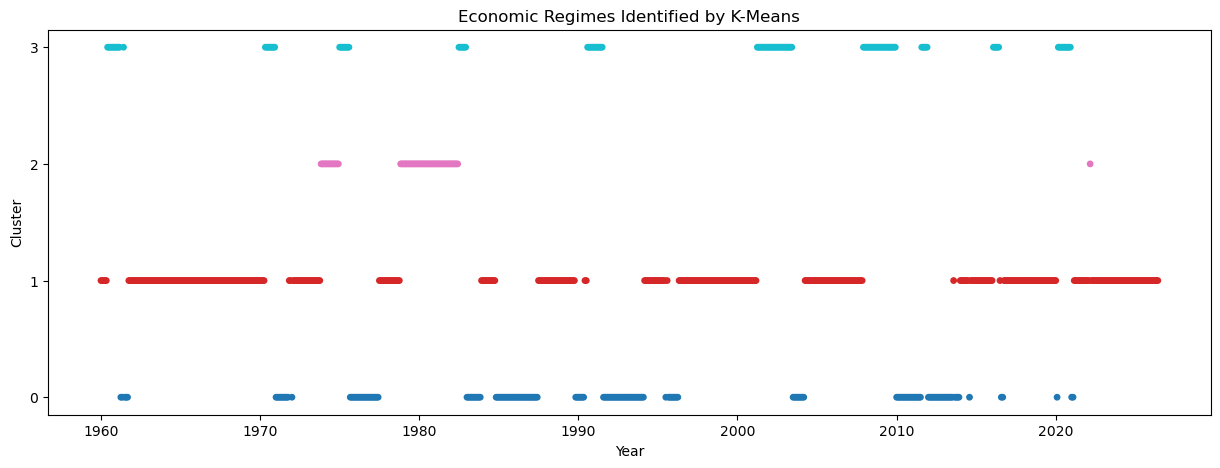

In [1126]:
# Plot cluster assignments over time
plt.figure(figsize=(15, 5))

plt.scatter(
    ml_data["Date"],
    ml_data["Cluster"],
    c=ml_data["Cluster"],
    cmap="tab10",
    s=15
)

plt.title("Economic Regimes Identified by K-Means")
plt.xlabel("Year")
plt.ylabel("Cluster")
plt.yticks([0, 1, 2, 3])

plt.show()

<h3>Comparison with Historical Economic Conditions</h3>

To evaluate whether the clusters are economically meaningful, I compared the cluster
assignments with major periods in U.S. economic history. A strong historical relationship between the cluster characteristics and known
economic conditions would provide additional support for the interpretation of
the identified regimes.

In [1127]:
# Important historical periods for comparison
historical_periods = {
    "1960-61 Recession": ("1960-04-01", "1961-02-01"),
    "1962-65 Expansion": ("1962-01-01", "1965-12-01"),
    "1966-69 Late Expansion": ("1966-01-01", "1969-11-01"),
    "1970 Recession": ("1969-12-01", "1970-11-01"),
    "1971-72 Recovery": ("1971-01-01", "1972-12-01"),
    "1973-75 Oil Shock/Recession": ("1973-11-01", "1975-03-01"),
    "1976-78 Recovery/Inflation": ("1976-01-01", "1978-12-01"),
    "1979-80 Inflation/Tightening/Recession": ("1979-01-01", "1980-12-01"),
    "1981-82 Recession": ("1981-07-01", "1982-11-01"),
    "1983-86 Recovery": ("1983-01-01", "1986-12-01"),
    "1987-89 Expansion": ("1987-01-01", "1989-12-01"),
    "1990-91 Recession": ("1990-07-01", "1991-03-01"),
    "1992-95 Expansion": ("1992-01-01", "1995-12-01"),
    "1996-99 Strong Expansion": ("1996-01-01", "1999-12-01"),
    "2000-02 Dot-Com Bust/Recession Era": ("2000-01-01", "2002-12-01"),
    "2003-06 Expansion": ("2003-01-01", "2006-12-01"),
    "2007 Pre-Crisis": ("2007-01-01", "2007-11-01"),
    "2007-09 Great Recession": ("2007-12-01", "2009-06-01"),
    "2009-12 Early Recovery": ("2009-07-01", "2012-12-01"),
    "2013-15 Expansion": ("2013-01-01", "2015-12-01"),
    "2016-19 Expansion": ("2016-01-01", "2019-12-01"),
    "2020 COVID Recession": ("2020-02-01", "2020-04-01"),
    "2020-21 Recovery": ("2020-05-01", "2021-12-01"),
    "2022-23 Inflation/Tightening": ("2022-01-01", "2023-12-01"),
    "2024-26 Recent Period": ("2024-01-01", "2026-06-01")
}

<h3>Historical Periods Used for Comparison</h3>

Sources:
- NBER: U.S. Business Cycle Expansions and Contractions
- Federal Reserve History: The Great Inflation and The Great Moderation

In [1128]:
historical_results = []

for period, (start, end) in historical_periods.items():

    period_data = ml_data[
        (ml_data["Date"] >= start) &
        (ml_data["Date"] <= end)
    ]

    percentages = period_data["Cluster"].value_counts(normalize=True) * 100

    historical_results.append([
        period,
        percentages.get(0, 0),
        percentages.get(1, 0),
        percentages.get(2, 0),
        percentages.get(3, 0)
    ])

historical_results = pd.DataFrame(
    historical_results,
    columns=["Period", "Cluster 0", "Cluster 1", "Cluster 2", "Cluster 3"]
)

historical_results.round(1)

,Period,Cluster 0,Cluster 1,Cluster 2,Cluster 3
0,1960-61 Recession,0.0,18.2,0.0,81.8
1,1962-65 Expansion,0.0,100.0,0.0,0.0
2,1966-69 Late Expansion,0.0,100.0,0.0,0.0
3,1970 Recession,0.0,41.7,0.0,58.3
4,1971-72 Recovery,45.8,54.2,0.0,0.0
5,1973-75 Oil Shock/Recession,0.0,0.0,82.4,17.6
6,1976-78 Recovery/Inflation,50.0,44.4,5.6,0.0
7,1979-80 Inflation/Tightening/Recession,0.0,0.0,100.0,0.0
8,1981-82 Recession,0.0,0.0,70.6,29.4
9,1983-86 Recovery,77.1,22.9,0.0,0.0


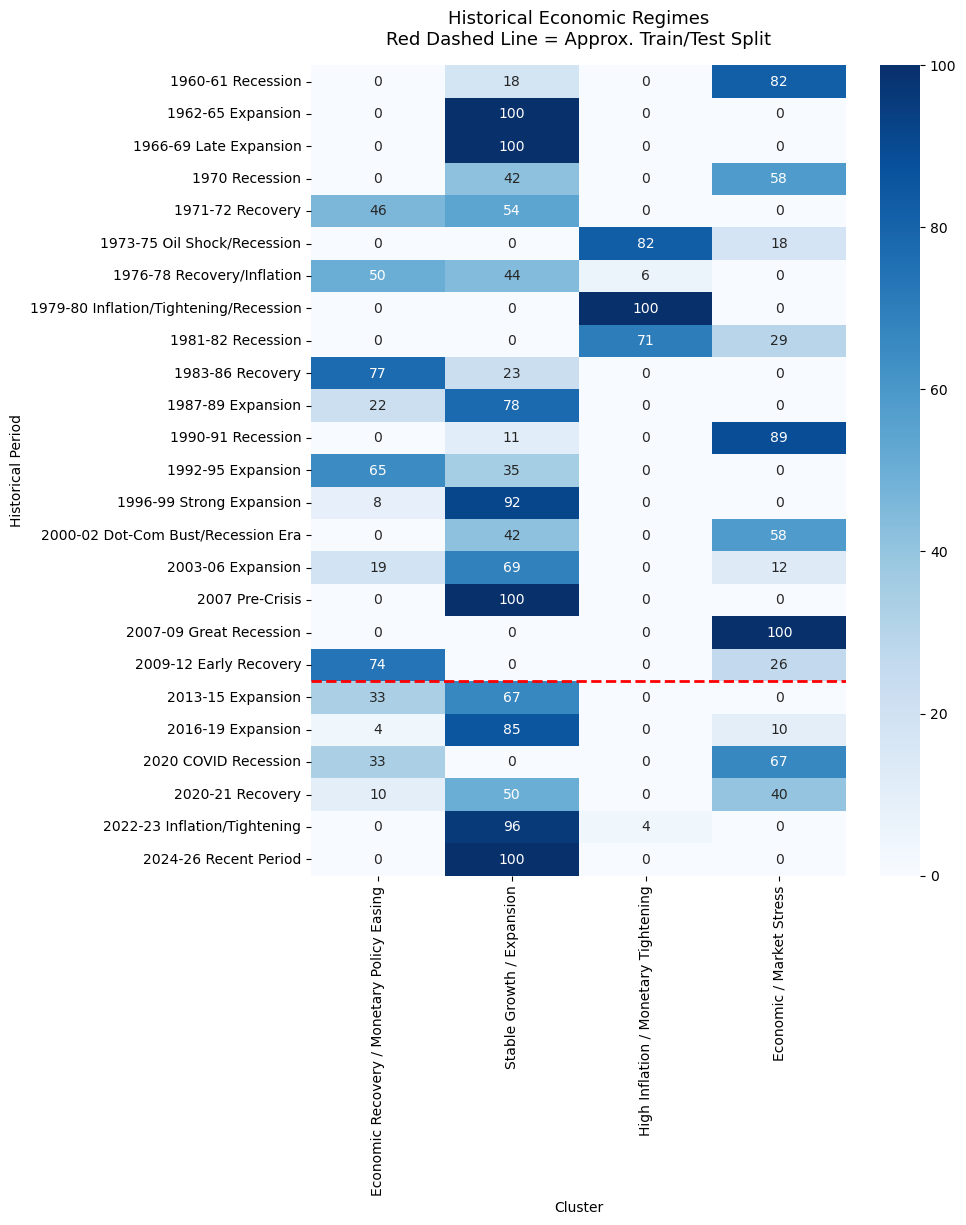

In [1129]:
# Use the historical period as the row label
history_heatmap = historical_results.set_index("Period")

# Tentative names based on the cluster characteristics
cluster_names = {
    "Cluster 0": "Economic Recovery / Monetary Policy Easing",
    "Cluster 1": "Stable Growth / Expansion",
    "Cluster 2": "High Inflation / Monetary Tightening",
    "Cluster 3": "Economic / Market Stress"
}

# Replace cluster numbers with descriptive names
history_heatmap = history_heatmap.rename(columns=cluster_names)

plt.figure(figsize=(10, 12))

sns.heatmap(
    history_heatmap,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Cluster Distribution Across Historical Economic Periods")
plt.xlabel("Cluster")
plt.ylabel("Historical Period")

plt.tight_layout()

# Mark the approximate train/test boundary
plt.axhline(
    y=19,
    color="red",
    linestyle="--",
    linewidth=2
)

# Add explanation to chart title
plt.title(
    "Historical Economic Regimes\n"
    "Red Dashed Line = Approx. Train/Test Split",
    fontsize=13,
    pad=15
)
plt.show()

<h3>Historical Validation of the Identified Regimes</h3>

The clusters show meaningful relationships with several historical economic periods. Cluster 2 accounts for 100% of the 1979–80 inflation and tightening period, while Cluster 3 accounts for 100% of the 2007–09 Great Recession period.

Cluster 0 is common during the 1983–86 recovery (77%) and 2009–12 early recovery (74%). Cluster 1 dominates the 1996–99 strong expansion (92%) and 2016–19 expansion (85%).

The results also show limitations. For example, most of 2022–23 is assigned to Cluster 1 rather than Cluster 2. This suggests that the clusters capture combinations of economic conditions rather than matching historical event labels exactly.

In [1130]:
#Calculate the percentage of months assigned to each cluster separately for the training and test periods.
cluster_comparison = pd.crosstab(
    ml_data["Dataset"],
    ml_data["Cluster"],
    normalize="index"
) * 100

cluster_comparison.round(1)

Cluster,0,1,2,3
Dataset,,,,
Test,9.4,80.6,0.6,9.4
Train,26.6,48.3,9.1,16.0


<b>Train vs. Test Cluster Comparison</b>

Cluster 1 (Stable Growth / Expansion) is the most common regime in both datasets, increasing from 48.3% in training to 80.6% in testing.

Cluster 0 (Economic Recovery / Policy Easing) decreases from 26.6% to 9.4%, while Cluster 3 (Economic / Market Stress) decreases from 16.0% to 9.4%. Cluster 2 (High Inflation / Monetary Tightening) is rarely observed in the test period.

The results suggest that the later period is dominated by conditions resembling the stable-growth cluster.

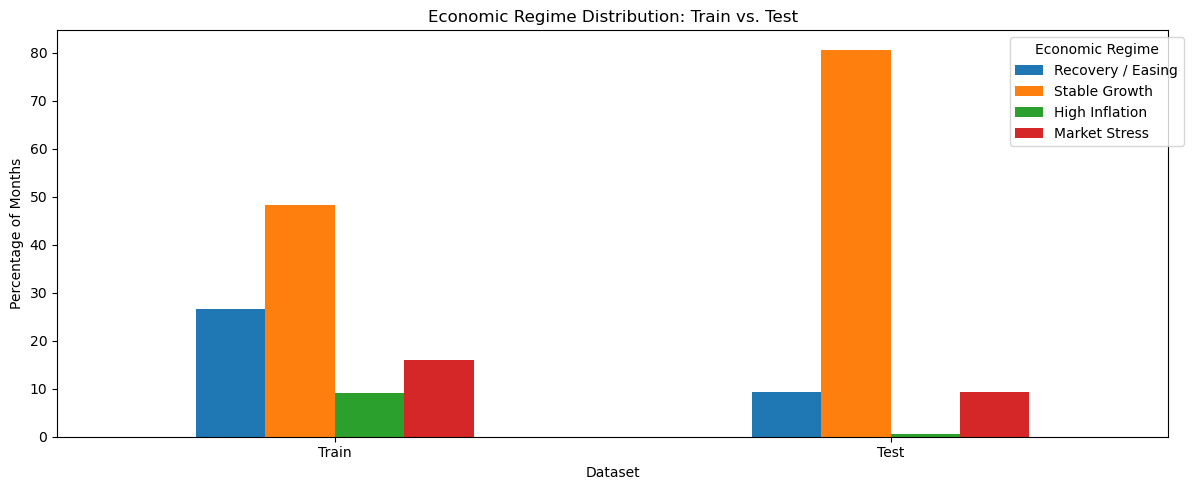

In [1131]:
# Rename clusters
cluster_comparison.columns = [
    "Recovery / Easing",
    "Stable Growth",
    "High Inflation",
    "Market Stress"
]

# Create bar chart
cluster_comparison.loc[["Train", "Test"]].plot(kind="bar", figsize=(12, 5))

plt.title("Economic Regime Distribution: Train vs. Test")
plt.xlabel("Dataset")
plt.ylabel("Percentage of Months")
plt.xticks(rotation=0)
plt.legend(title="Economic Regime", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

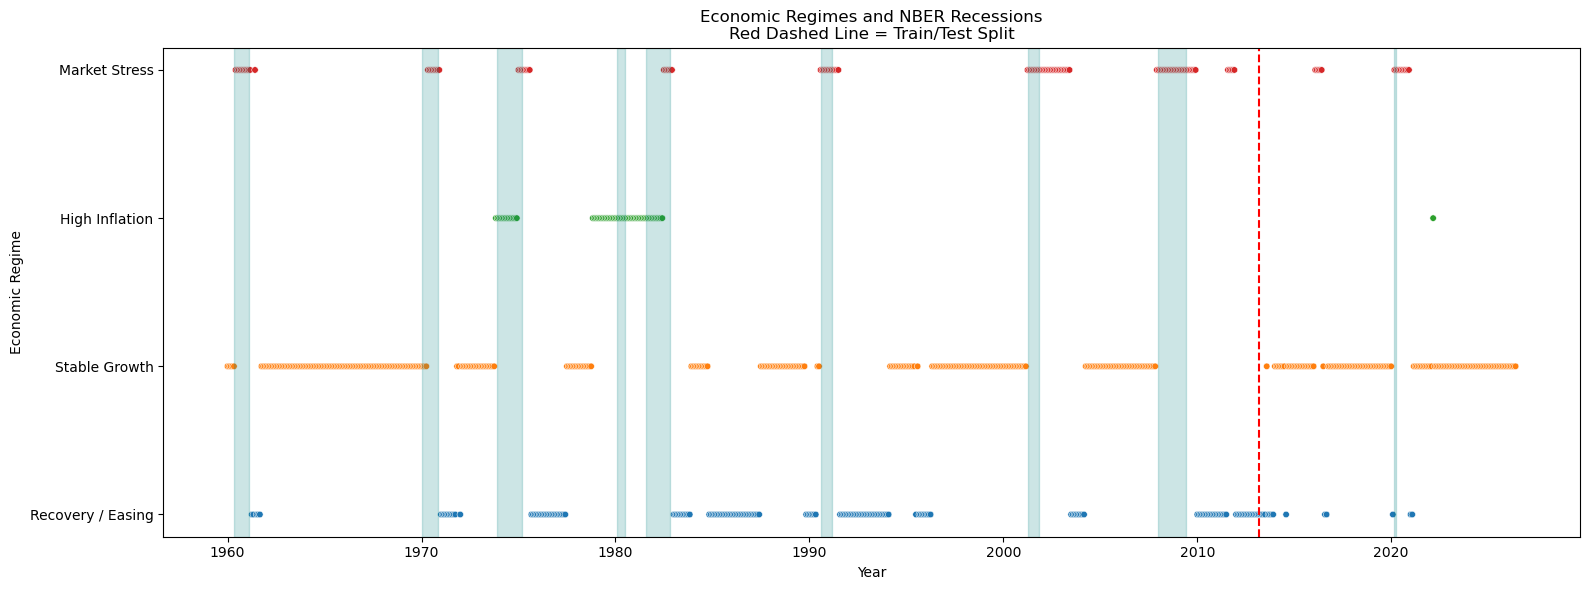

In [1132]:
#NBER recession months
recessions = [
    ("1960-05", "1961-02"),
    ("1970-01", "1970-11"),
    ("1973-12", "1975-03"),
    ("1980-02", "1980-07"),
    ("1981-08", "1982-11"),
    ("1990-08", "1991-03"),
    ("2001-04", "2001-11"),
    ("2008-01", "2009-06"),
    ("2020-03", "2020-04")
]

plt.figure(figsize=(16, 6))

# Plot monthly economic regimes
sns.scatterplot(
    data=ml_data,
    x="Date",
    y="Cluster",
    hue="Cluster",
    palette="tab10",
    s=22,
    legend=False
)

# Highlight NBER recession months
for start, end in recessions:
    plt.axvspan(start, end, color="teal", alpha=0.2)

plt.axvline(test_data["Date"].min(), color="red", linestyle="--") # Mark the train/test split

# Label economic regimes
plt.yticks(
    [0, 1, 2, 3],
    ["Recovery / Easing", "Stable Growth", "High Inflation", "Market Stress"]
)

plt.title("Economic Regimes and NBER Recessions\nRed Dashed Line = Train/Test Split")
plt.xlabel("Year")
plt.ylabel("Economic Regime")

plt.tight_layout()
plt.show()

This chart visually connects the PCA/K-Means results with official recession periods while distinguishing the training and test observations.

<h2>13. Conclusion</h2>

This assignment used PCA and K-Means clustering to identify four economic and financial market regimes using historical U.S. data. The identified clusters show relationships with economic expansions, inflationary periods, recoveries, and recessions. Overall, the analysis demonstrates how unsupervised machine learning can help identify patterns in economic and financial market conditions.